## Loading And Exploratory Data Analysis (EDA)

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_excel("data/PJMW_MW_Hourly.xlsx")

# Display first 5 rows
df.head()

,Datetime,PJMW_MW
0,2002-12-31 01:00:00,5077
1,2002-12-31 02:00:00,4939
2,2002-12-31 03:00:00,4885
3,2002-12-31 04:00:00,4857
4,2002-12-31 05:00:00,4930


In [3]:
# Dataset dimensions
print("Shape:", df.shape)

# Column information
df.info()

# Statistical summary
df.describe()

Shape: (143206, 2)
<class 'pandas.DataFrame'>
RangeIndex: 143206 entries, 0 to 143205
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   Datetime  143206 non-null  datetime64[us]
 1   PJMW_MW   143206 non-null  int64         
dtypes: datetime64[us](1), int64(1)
memory usage: 2.2 MB


,Datetime,PJMW_MW
count,143206,143206.000000
mean,2010-06-02 03:39:50.656815,5602.375089
min,2002-04-01 01:00:00,487.000000
25%,2006-05-02 03:15:00,4907.000000
50%,2010-06-02 04:30:00,5530.000000
75%,2014-07-03 06:45:00,6252.000000
max,2018-08-03 00:00:00,9594.000000
std,NaN,979.142872


In [4]:
# Missing values
print("Missing values:")
print(df.isnull().sum())

# Duplicate rows
print("\nDuplicate rows:")
print(df.duplicated().sum())

# Duplicate timestamps
print("\nDuplicate timestamps:")
print(df["Datetime"].duplicated().sum())

Missing values:
Datetime    0
PJMW_MW     0
dtype: int64

Duplicate rows:
0

Duplicate timestamps:
4


## Sort the data chronologically

In [5]:
# Sort by date and time
df = df.sort_values("Datetime")

# Reset index
df = df.reset_index(drop=True)

# Check chronological order
print(df.head())
print(df.tail())

             Datetime  PJMW_MW
0 2002-04-01 01:00:00     4374
1 2002-04-01 02:00:00     4306
2 2002-04-01 03:00:00     4322
3 2002-04-01 04:00:00     4359
4 2002-04-01 05:00:00     4436
                  Datetime  PJMW_MW
143201 2018-08-02 20:00:00     6545
143202 2018-08-02 21:00:00     6496
143203 2018-08-02 22:00:00     6325
143204 2018-08-02 23:00:00     5892
143205 2018-08-03 00:00:00     5489


In [6]:
print(df["Datetime"].is_monotonic_increasing)

True


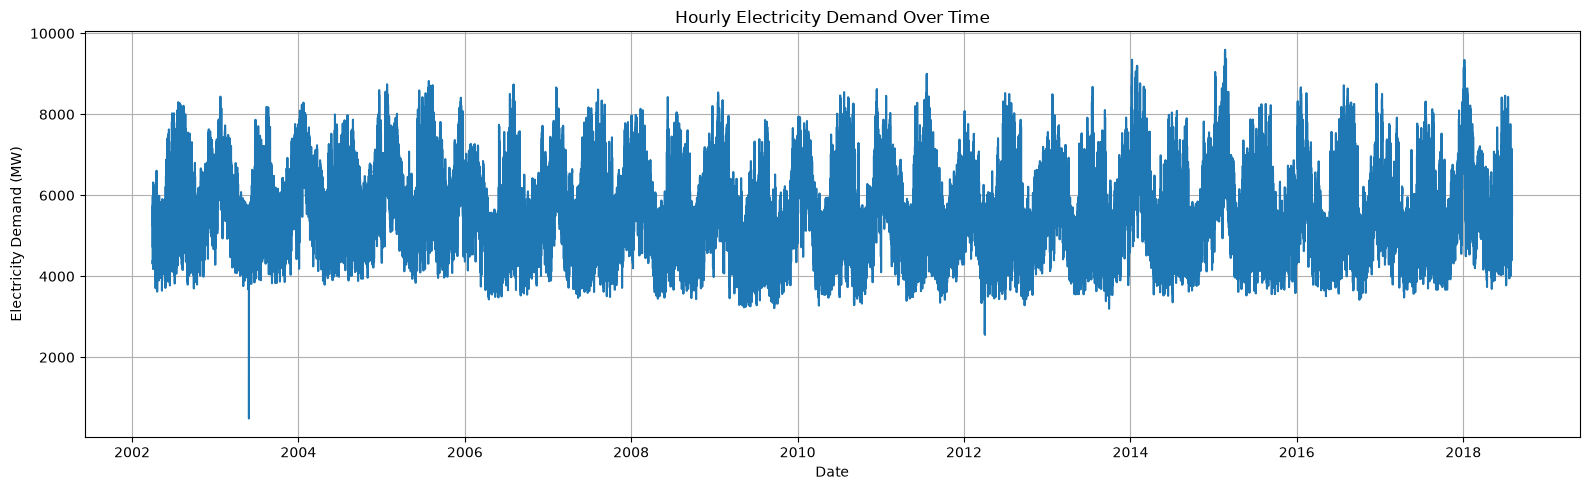

In [7]:
plt.figure(figsize=(16, 5))

plt.plot(df["Datetime"], df["PJMW_MW"])

plt.title("Hourly Electricity Demand Over Time")
plt.xlabel("Date")
plt.ylabel("Electricity Demand (MW)")

plt.grid(True)
plt.tight_layout()
plt.show()

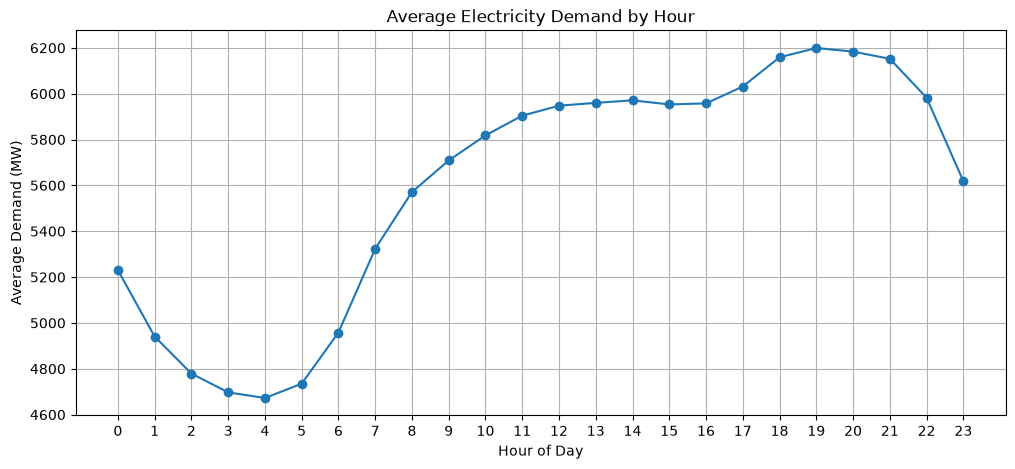

In [8]:
df["Hour"] = df["Datetime"].dt.hour

hourly_avg = df.groupby("Hour")["PJMW_MW"].mean()

plt.figure(figsize=(12, 5))

plt.plot(hourly_avg.index, hourly_avg.values, marker="o")

plt.title("Average Electricity Demand by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Demand (MW)")

plt.xticks(range(24))
plt.grid(True)

plt.show()

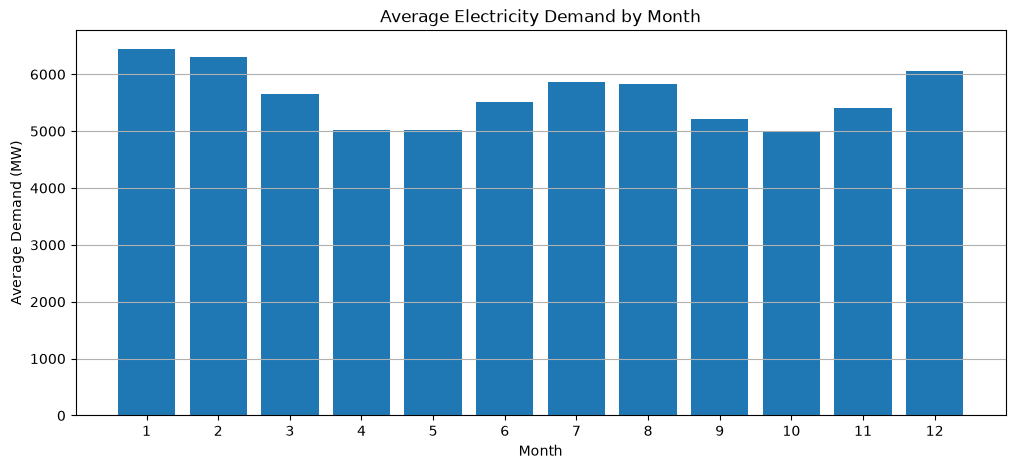

In [9]:
df["Month"] = df["Datetime"].dt.month

monthly_avg = df.groupby("Month")["PJMW_MW"].mean()

plt.figure(figsize=(12, 5))

plt.bar(monthly_avg.index, monthly_avg.values)

plt.title("Average Electricity Demand by Month")
plt.xlabel("Month")
plt.ylabel("Average Demand (MW)")

plt.xticks(range(1, 13))
plt.grid(axis="y")

plt.show()

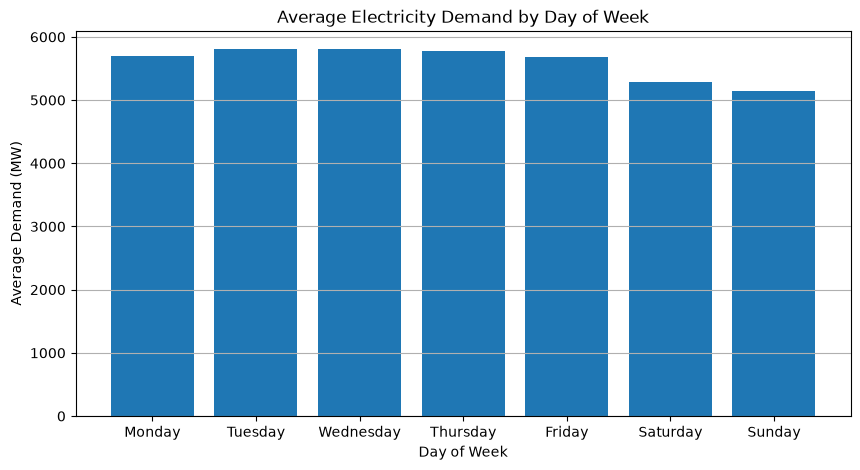

In [10]:
df["DayOfWeek"] = df["Datetime"].dt.day_of_week
day_avg = df.groupby("DayOfWeek")["PJMW_MW"].mean()

plt.figure(figsize=(10, 5))

plt.bar(day_avg.index, day_avg.values)

plt.title("Average Electricity Demand by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Demand (MW)")

plt.xticks(
    range(7),
    ["Monday", "Tuesday", "Wednesday",
     "Thursday", "Friday", "Saturday", "Sunday"]
)

plt.grid(axis="y")
plt.show()

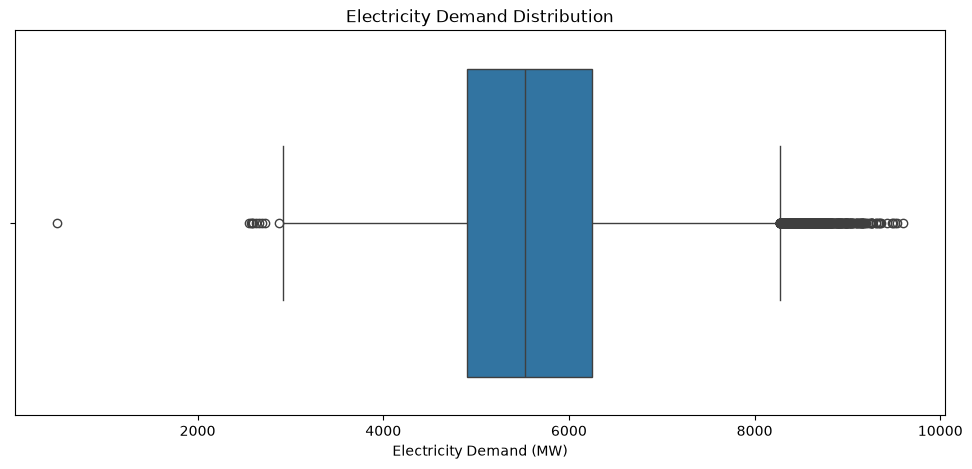

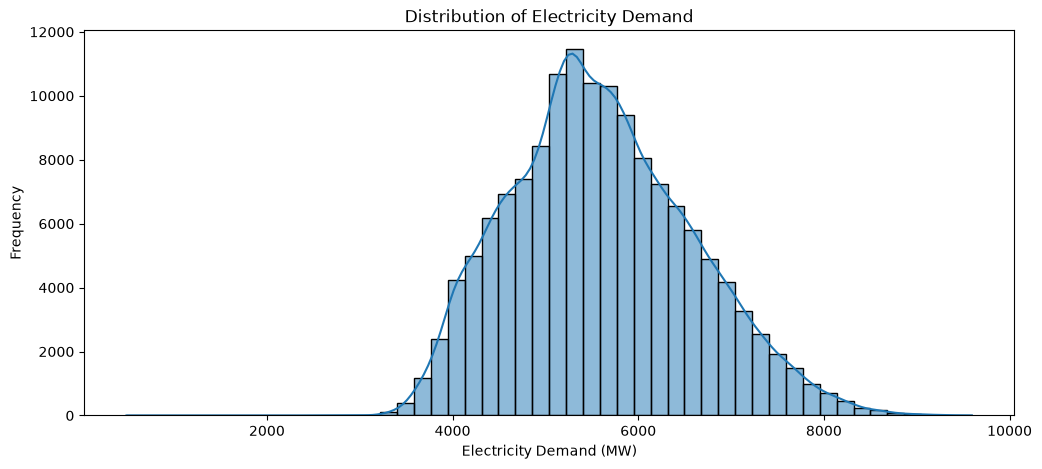

In [11]:
plt.figure(figsize=(12, 5))

sns.boxplot(x=df["PJMW_MW"])

plt.title("Electricity Demand Distribution")
plt.xlabel("Electricity Demand (MW)")

plt.show()

plt.figure(figsize=(12, 5))

sns.histplot(df["PJMW_MW"], bins=50, kde=True)

plt.title("Distribution of Electricity Demand")
plt.xlabel("Electricity Demand (MW)")
plt.ylabel("Frequency")

plt.show()

## Data Preprocessing & Feature Engineering

## Handling Duplicate Timestamps and Missing Hours

In [12]:
# Check duplicate timestamps
duplicate_dates = df[df["Datetime"].duplicated(keep=False)]

print("Duplicate timestamp records:")
print(duplicate_dates)

Duplicate timestamp records:
                  Datetime  PJMW_MW  Hour  Month  DayOfWeek
110327 2014-11-02 02:00:00     4571     2     11          6
110328 2014-11-02 02:00:00     4613     2     11          6
119063 2015-11-01 02:00:00     3927     2     11          6
119064 2015-11-01 02:00:00     3832     2     11          6
127967 2016-11-06 02:00:00     4114     2     11          6
127968 2016-11-06 02:00:00     4089     2     11          6
136703 2017-11-05 02:00:00     3984     2     11          6
136704 2017-11-05 02:00:00     4042     2     11          6


In [13]:
# Aggregate duplicate timestamps
df = df.groupby("Datetime", as_index=False)["PJMW_MW"].mean()

# Sort chronologically
df = df.sort_values("Datetime").reset_index(drop=True)

print("New shape:", df.shape)

print("Remaining duplicate timestamps:",
      df["Datetime"].duplicated().sum())

New shape: (143202, 2)
Remaining duplicate timestamps: 0


In [14]:
df = df.set_index("Datetime")

full_index = pd.date_range(
    start=df.index.min(),
    end=df.index.max(),
    freq="h"
)

df = df.reindex(full_index)

df.index.name = "Datetime"

print(df.isnull().sum())

PJMW_MW    30
dtype: int64


In [15]:
df["PJMW_MW"] = df["PJMW_MW"].interpolate(method="time")

print("Missing values:", df["PJMW_MW"].isnull().sum())

Missing values: 0


In [16]:
df["Hour"] = df.index.hour

df["DayOfWeek"] = df.index.day_of_week

df["Day"] = df.index.day

df["Month"] = df.index.month

df["Year"] = df.index.year

df["IsWeekend"] = (df["DayOfWeek"] >= 5).astype(int)

In [17]:
# Hour cyclical features
df["Hour_sin"] = np.sin(2 * np.pi * df["Hour"] / 24)

df["Hour_cos"] = np.cos(2 * np.pi * df["Hour"] / 24)

# Month cyclical features
df["Month_sin"] = np.sin(2 * np.pi * df["Month"] / 12)

df["Month_cos"] = np.cos(2 * np.pi * df["Month"] / 12)

In [18]:
df["Lag_1"] = df["PJMW_MW"].shift(1)

df["Lag_24"] = df["PJMW_MW"].shift(24)

df["Lag_168"] = df["PJMW_MW"].shift(168)

In [19]:
df["Rolling_Mean_24"] = (
    df["PJMW_MW"].shift(1).rolling(24).mean()
)

df["Rolling_Mean_168"] = (
    df["PJMW_MW"].shift(1).rolling(168).mean()
)

df["Rolling_Std_24"] = (
    df["PJMW_MW"].shift(1).rolling(24).std()
)

In [20]:
df_model = df.dropna().copy()

print("Final shape:", df_model.shape)

print("Missing values:", df_model.isnull().sum().sum())

Final shape: (143064, 17)
Missing values: 0


## Train, Validation & Test Split

In [21]:
train_size = int(len(df_model) * 0.70)

val_size = int(len(df_model) * 0.15)

train = df_model.iloc[:train_size].copy()

val = df_model.iloc[train_size:train_size + val_size].copy()

test = df_model.iloc[train_size + val_size:].copy()

print("Train:", train.shape)

print("Validation:", val.shape)

print("Test:", test.shape)

Train: (100144, 17)
Validation: (21459, 17)
Test: (21461, 17)


In [22]:
print("Train:", train.index.min(), "to", train.index.max())

print("Validation:", val.index.min(), "to", val.index.max())

print("Test:", test.index.min(), "to", test.index.max())

Train: 2002-04-08 01:00:00 to 2013-09-09 16:00:00
Validation: 2013-09-09 17:00:00 to 2016-02-20 19:00:00
Test: 2016-02-20 20:00:00 to 2018-08-03 00:00:00


In [23]:
feature_cols = [
    "Hour",
    "DayOfWeek",
    "Day",
    "Month",
    "Year",
    "IsWeekend",
    "Hour_sin",
    "Hour_cos",
    "Month_sin",
    "Month_cos",
    "Lag_1",
    "Lag_24",
    "Lag_168",
    "Rolling_Mean_24",
    "Rolling_Mean_168",
    "Rolling_Std_24"
]

X_train = train[feature_cols]

y_train = train["PJMW_MW"]

print("X_train shape:", X_train.shape)

print("y_train shape:", y_train.shape)

X_train shape: (100144, 16)
y_train shape: (100144,)


In [24]:
import os

os.makedirs("artifacts", exist_ok=True)

df_model.to_csv("artifacts/processed_data.csv")

print("Saved successfully!")

Saved successfully!


## Model Building

## Stage 3: Model Building

### 3.1 Baseline Forecasting Models

Before building advanced forecasting models, we will implement
baseline models to establish a benchmark for comparison.

1. Naive Forecast
2. Seasonal Naive Forecast

In [25]:
def naive_forecast(history, horizon):

    last_value = history[-1]

    predictions = np.repeat(last_value, horizon)

    return predictions

In [26]:
def seasonal_naive_forecast(history, horizon, seasonality=24):

    values = list(history)

    predictions = []

    for i in range(horizon):

        prediction = values[-seasonality]

        predictions.append(prediction)

        values.append(prediction)

    return np.array(predictions)

In [27]:
history = train["PJMW_MW"].values

test_naive = naive_forecast(history, 43)

test_seasonal = seasonal_naive_forecast(history, 43)

print("Naive forecast length:", len(test_naive))

print("Seasonal forecast length:", len(test_seasonal))

print("\nNaive forecast:")
print(test_naive[:5])

print("\nSeasonal forecast:")
print(test_seasonal[:5])

Naive forecast length: 43
Seasonal forecast length: 43

Naive forecast:
[6346. 6346. 6346. 6346. 6346.]

Seasonal forecast:
[6084. 6215. 6085. 5955. 6082.]


### 3.2 Baseline Model Evaluation

We will evaluate the Naive and Seasonal Naive forecasting models
using multiple forecast horizons.

Evaluation metrics:
- MAE
- RMSE
- MAPE

The forecasts will be generated recursively where applicable.

In [28]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def calculate_metrics(actual, predicted):

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(mean_squared_error(actual, predicted))

    mape = np.mean(np.abs((actual - predicted) / actual)) * 100

    return mae, rmse, mape

In [29]:
evaluation_horizons = [1, 3, 6, 8, 24, 43, 48, 168]

results = []

history = train["PJMW_MW"].values

actual_values = val["PJMW_MW"].values

for horizon in evaluation_horizons:

    actual = actual_values[:horizon]

    # Naive Forecast
    predicted_naive = naive_forecast(history, horizon)

    mae, rmse, mape = calculate_metrics(actual, predicted_naive)

    results.append({
        "Model": "Naive",
        "Horizon": horizon,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    })

    # Seasonal Naive Forecast
    predicted_seasonal = seasonal_naive_forecast(
        history,
        horizon
    )

    mae, rmse, mape = calculate_metrics(actual, predicted_seasonal)

    results.append({
        "Model": "Seasonal Naive",
        "Horizon": horizon,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    })

baseline_results = pd.DataFrame(results)

baseline_results

,Model,Horizon,MAE,RMSE,MAPE
0,Naive,1,143.000000,143.000000,2.203729
1,Seasonal Naive,1,405.000000,405.000000,6.241331
2,Naive,3,119.000000,120.602653,1.839779
3,Seasonal Naive,3,337.000000,343.152541,5.211800
4,Naive,6,129.166667,135.797030,2.021233
5,Seasonal Naive,6,399.166667,407.191806,6.242191
6,Naive,8,336.250000,505.379808,6.008541
7,Seasonal Naive,8,412.000000,419.531286,6.786922
8,Naive,24,911.291667,1133.091917,17.333665
9,Seasonal Naive,24,629.958333,741.563691,10.225412


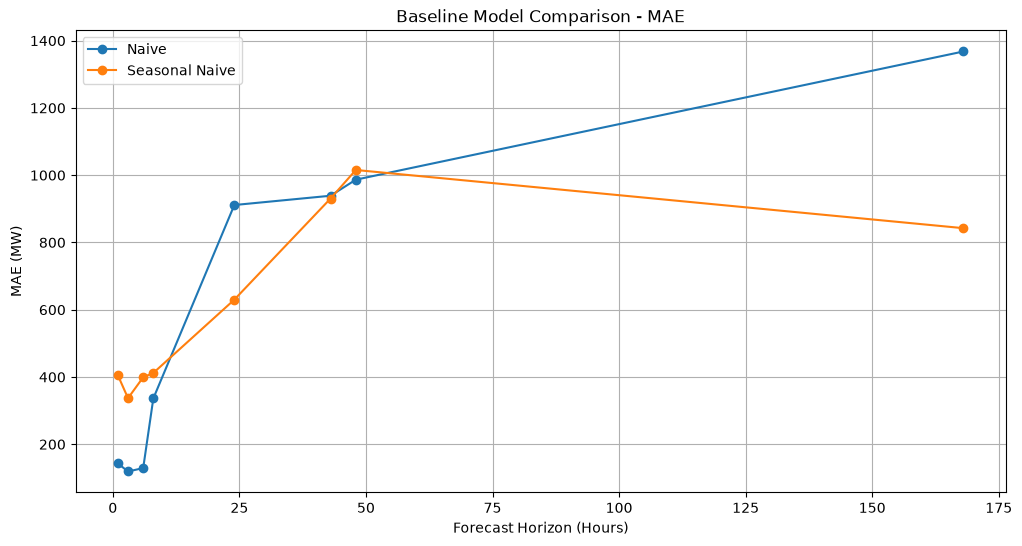

In [30]:
plt.figure(figsize=(12, 6))

for model in baseline_results["Model"].unique():

    model_data = baseline_results[
        baseline_results["Model"] == model
    ]

    plt.plot(
        model_data["Horizon"],
        model_data["MAE"],
        marker="o",
        label=model
    )

plt.xlabel("Forecast Horizon (Hours)")
plt.ylabel("MAE (MW)")
plt.title("Baseline Model Comparison - MAE")
plt.legend()
plt.grid(True)

plt.show()

### 3.3 ARIMA Model

ARIMA (AutoRegressive Integrated Moving Average) is a statistical
time-series forecasting model.

It uses:
- Autoregressive component (AR)
- Differencing component (I)
- Moving Average component (MA)

We will initially use ARIMA(1,1,1) as a baseline configuration.
The model parameters will be tuned in the hyperparameter tuning stage.

In [31]:
from statsmodels.tsa.arima.model import ARIMA

In [32]:
def arima_forecast(history, horizon, order=(1, 1, 1)):

    model = ARIMA(history, order=order)

    model_fit = model.fit()

    predictions = model_fit.forecast(steps=horizon)

    return np.array(predictions)

In [33]:
arima_test = arima_forecast(history, 43)

print("Forecast length:", len(arima_test))

print("First 5 predictions:")
print(arima_test[:5])

Forecast length: 43
First 5 predictions:
[6461.98183685 6538.16832435 6588.21392662 6621.08802791 6642.68246351]


In [34]:
# Forecast the maximum evaluation horizon once

max_horizon = max(evaluation_horizons)

arima_predictions = arima_forecast(
    history,
    max_horizon
)

arima_results = []

for horizon in evaluation_horizons:

    actual = actual_values[:horizon]

    predicted = arima_predictions[:horizon]

    mae, rmse, mape = calculate_metrics(actual, predicted)

    arima_results.append({
        "Model": "ARIMA",
        "Horizon": horizon,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    })

arima_results = pd.DataFrame(arima_results)

arima_results

,Model,Horizon,MAE,RMSE,MAPE
0,ARIMA,1,27.018163,27.018163,0.416369
1,ARIMA,3,82.466805,96.186494,1.277902
2,ARIMA,6,182.673064,239.157527,2.894545
3,ARIMA,8,457.191237,682.417788,8.166375
4,ARIMA,24,1035.689654,1297.920905,20.188800
5,ARIMA,43,1029.178948,1231.609515,18.783077
6,ARIMA,48,1032.324466,1216.899644,18.244050
7,ARIMA,168,1565.255276,1789.340121,33.989211


In [35]:
all_results = pd.concat(
    [baseline_results, arima_results],
    ignore_index=True
)

all_results

,Model,Horizon,MAE,RMSE,MAPE
0,Naive,1,143.000000,143.000000,2.203729
1,Seasonal Naive,1,405.000000,405.000000,6.241331
2,Naive,3,119.000000,120.602653,1.839779
3,Seasonal Naive,3,337.000000,343.152541,5.211800
4,Naive,6,129.166667,135.797030,2.021233
5,Seasonal Naive,6,399.166667,407.191806,6.242191
6,Naive,8,336.250000,505.379808,6.008541
7,Seasonal Naive,8,412.000000,419.531286,6.786922
8,Naive,24,911.291667,1133.091917,17.333665
9,Seasonal Naive,24,629.958333,741.563691,10.225412


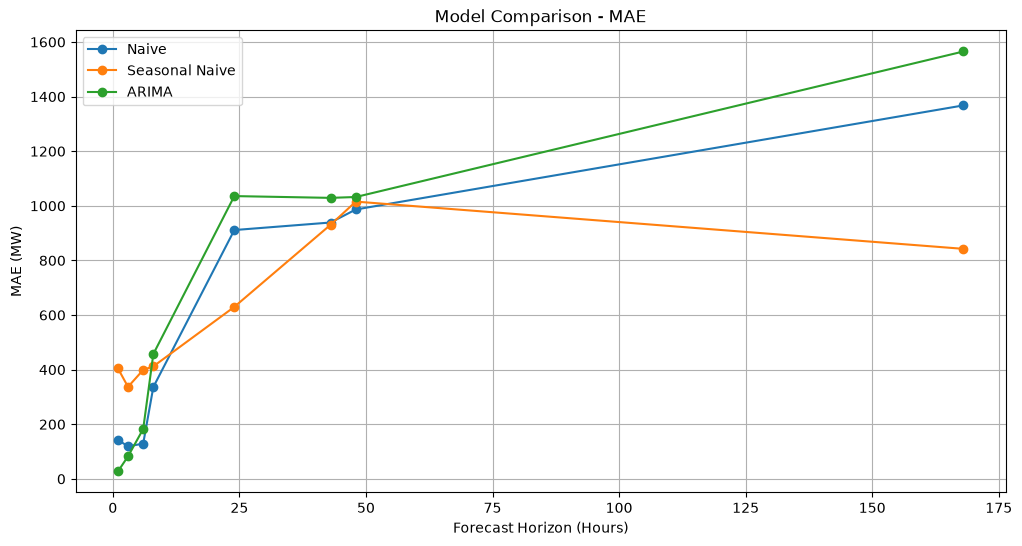

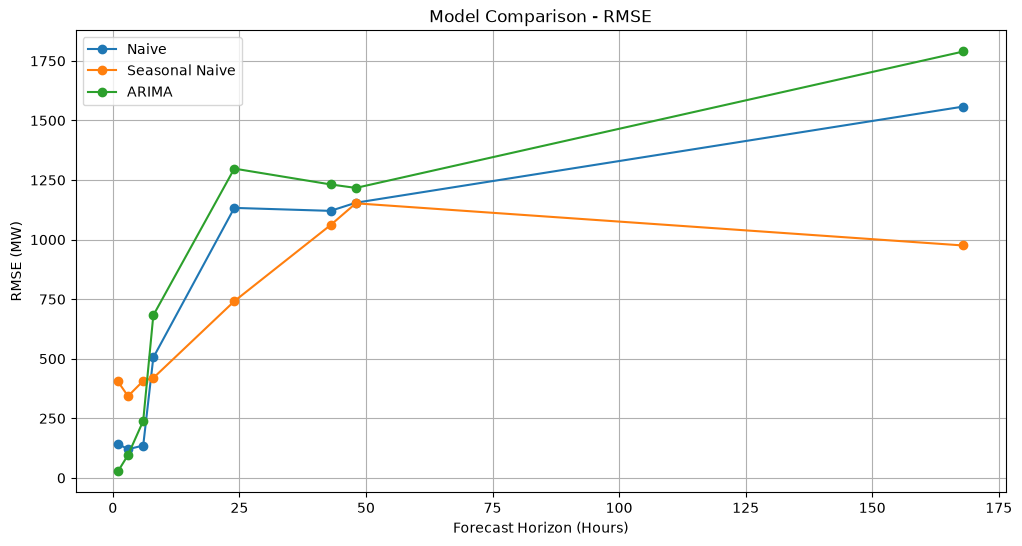

In [36]:
plt.figure(figsize=(12, 6))

for model in all_results["Model"].unique():

    model_data = all_results[
        all_results["Model"] == model
    ]

    plt.plot(
        model_data["Horizon"],
        model_data["MAE"],
        marker="o",
        label=model
    )

plt.xlabel("Forecast Horizon (Hours)")
plt.ylabel("MAE (MW)")
plt.title("Model Comparison - MAE")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 6))

for model in all_results["Model"].unique():

    model_data = all_results[
        all_results["Model"] == model
    ]

    plt.plot(
        model_data["Horizon"],
        model_data["RMSE"],
        marker="o",
        label=model
    )

plt.xlabel("Forecast Horizon (Hours)")
plt.ylabel("RMSE (MW)")
plt.title("Model Comparison - RMSE")
plt.legend()
plt.grid(True)

plt.show()

### 3.4 SARIMA Model

SARIMA (Seasonal AutoRegressive Integrated Moving Average)
extends ARIMA by incorporating seasonal patterns.

Since our electricity demand data is hourly and shows daily
seasonality, we will initially use a seasonal period of 24 hours.

Initial configuration:

SARIMA(1,1,1)(1,1,1,24)

The parameters will be tuned later.

In [37]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

In [38]:
def sarima_forecast(
    history,
    horizon,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 24)
):

    # Use the most recent one year of hourly data
    recent_history = history[-8760:]

    model = SARIMAX(
        recent_history,
        order=order,
        seasonal_order=seasonal_order,
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    model_fit = model.fit(disp=False)

    predictions = model_fit.forecast(steps=horizon)

    return np.array(predictions)

In [39]:
sarima_test = sarima_forecast(history, 43)

print("Forecast length:", len(sarima_test))

print("\nFirst 5 predictions:")
print(sarima_test[:5])

Forecast length: 43

First 5 predictions:
[6480.60089341 6533.04561717 6403.51589498 6252.19304489 6305.25996414]


In [40]:
# Forecast the maximum evaluation horizon

max_horizon = max(evaluation_horizons)

sarima_predictions = sarima_forecast(
    history,
    max_horizon
)

sarima_results = []

for horizon in evaluation_horizons:

    actual = actual_values[:horizon]

    predicted = sarima_predictions[:horizon]

    mae, rmse, mape = calculate_metrics(actual, predicted)

    sarima_results.append({
        "Model": "SARIMA",
        "Horizon": horizon,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    })

sarima_results = pd.DataFrame(sarima_results)

sarima_results

,Model,Horizon,MAE,RMSE,MAPE
0,SARIMA,1,8.399107,8.399107,0.129436
1,SARIMA,3,37.976276,45.113964,0.587973
2,SARIMA,6,109.417616,132.387925,1.716548
3,SARIMA,8,108.962259,127.106842,1.791608
4,SARIMA,24,397.356828,576.183739,6.108596
5,SARIMA,43,662.457424,815.548273,10.156347
6,SARIMA,48,746.615015,906.709216,11.076480
7,SARIMA,168,882.823931,1052.224911,17.546803


In [41]:
all_results = pd.concat(
    [
        baseline_results,
        arima_results,
        sarima_results
    ],
    ignore_index=True
)

all_results

,Model,Horizon,MAE,RMSE,MAPE
0,Naive,1,143.000000,143.000000,2.203729
1,Seasonal Naive,1,405.000000,405.000000,6.241331
2,Naive,3,119.000000,120.602653,1.839779
3,Seasonal Naive,3,337.000000,343.152541,5.211800
4,Naive,6,129.166667,135.797030,2.021233
5,Seasonal Naive,6,399.166667,407.191806,6.242191
6,Naive,8,336.250000,505.379808,6.008541
7,Seasonal Naive,8,412.000000,419.531286,6.786922
8,Naive,24,911.291667,1133.091917,17.333665
9,Seasonal Naive,24,629.958333,741.563691,10.225412


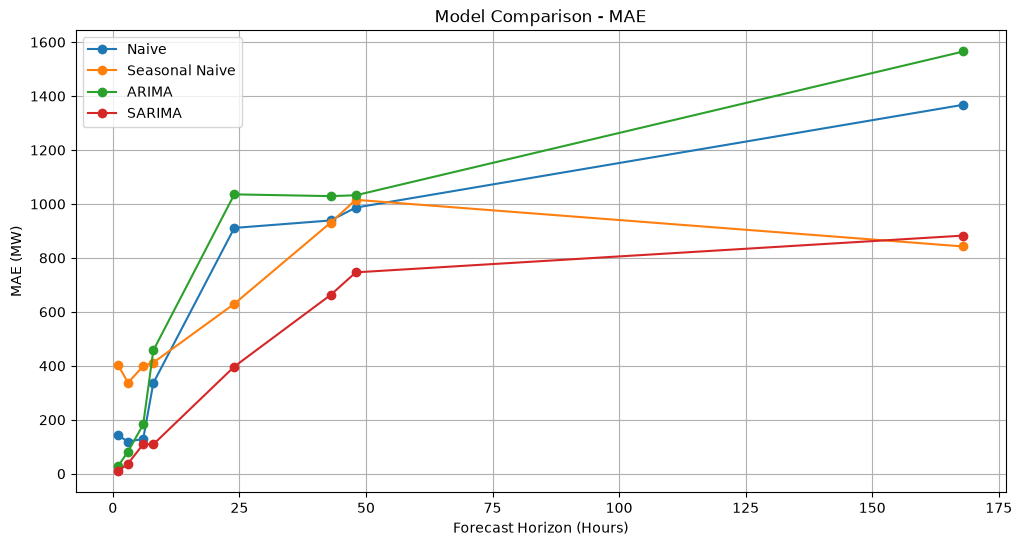

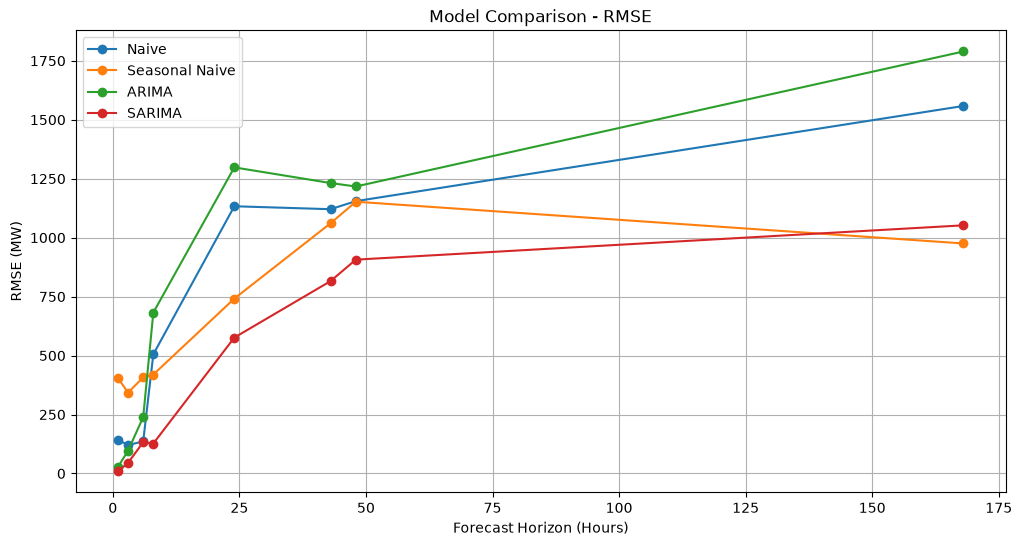

In [42]:
plt.figure(figsize=(12, 6))

for model in all_results["Model"].unique():

    model_data = all_results[
        all_results["Model"] == model
    ]

    plt.plot(
        model_data["Horizon"],
        model_data["MAE"],
        marker="o",
        label=model
    )

plt.xlabel("Forecast Horizon (Hours)")
plt.ylabel("MAE (MW)")
plt.title("Model Comparison - MAE")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 6))

for model in all_results["Model"].unique():

    model_data = all_results[
        all_results["Model"] == model
    ]

    plt.plot(
        model_data["Horizon"],
        model_data["RMSE"],
        marker="o",
        label=model
    )

plt.xlabel("Forecast Horizon (Hours)")
plt.ylabel("RMSE (MW)")
plt.title("Model Comparison - RMSE")
plt.legend()
plt.grid(True)
plt.show()

### 3.5 Random Forest Regressor

Random Forest is an ensemble machine learning algorithm that
combines predictions from multiple decision trees.

For electricity demand forecasting, we use calendar features,
lag features, and rolling statistical features.

For multi-step forecasting, predictions will be generated
recursively so that future actual demand values are not used.

In [43]:
from sklearn.ensemble import RandomForestRegressor
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [44]:
def random_forest_forecast(history, last_datetime, horizon, model):

    values = list(history)

    predictions = []

    future_dates = pd.date_range(
        start=last_datetime + pd.Timedelta(hours=1),
        periods=horizon,
        freq="h"
    )

    for future_date in future_dates:

        # Calendar features
        hour = future_date.hour
        day_of_week = future_date.day_of_week
        day = future_date.day
        month = future_date.month
        year = future_date.year
        is_weekend = int(day_of_week >= 5)

        # Cyclical features
        hour_sin = np.sin(2 * np.pi * hour / 24)
        hour_cos = np.cos(2 * np.pi * hour / 24)

        month_sin = np.sin(2 * np.pi * month / 12)
        month_cos = np.cos(2 * np.pi * month / 12)

        # Lag features
        lag_1 = values[-1]
        lag_24 = values[-24]
        lag_168 = values[-168]

        # Rolling features
        rolling_mean_24 = np.mean(values[-24:])
        rolling_mean_168 = np.mean(values[-168:])
        rolling_std_24 = np.std(values[-24:], ddof=1)

        # Create feature row
        feature_row = pd.DataFrame([{
            "Hour": hour,
            "DayOfWeek": day_of_week,
            "Day": day,
            "Month": month,
            "Year": year,
            "IsWeekend": is_weekend,
            "Hour_sin": hour_sin,
            "Hour_cos": hour_cos,
            "Month_sin": month_sin,
            "Month_cos": month_cos,
            "Lag_1": lag_1,
            "Lag_24": lag_24,
            "Lag_168": lag_168,
            "Rolling_Mean_24": rolling_mean_24,
            "Rolling_Mean_168": rolling_mean_168,
            "Rolling_Std_24": rolling_std_24
        }])

        # Ensure correct feature order
        feature_row = feature_row[feature_cols]

        # Predict next hour
        prediction = model.predict(feature_row)[0]

        predictions.append(prediction)

        # Append prediction for recursive forecasting
        values.append(prediction)

    return np.array(predictions)

In [45]:
rf_test = random_forest_forecast(
    history=history,
    last_datetime=train.index[-1],
    horizon=43,
    model=rf_model
)

print("Forecast length:", len(rf_test))

print("\nFirst 5 predictions:")
print(rf_test[:5])

Forecast length: 43

First 5 predictions:
[6424.54 6444.17 6325.04 6243.01 6189.81]


In [46]:
max_horizon = max(evaluation_horizons)

rf_predictions = random_forest_forecast(
    history=history,
    last_datetime=train.index[-1],
    horizon=max_horizon,
    model=rf_model
)

rf_results = []

for horizon in evaluation_horizons:

    actual = actual_values[:horizon]

    predicted = rf_predictions[:horizon]

    mae, rmse, mape = calculate_metrics(actual, predicted)

    rf_results.append({
        "Model": "Random Forest",
        "Horizon": horizon,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    })

rf_results = pd.DataFrame(rf_results)

rf_results

,Model,Horizon,MAE,RMSE,MAPE
0,Random Forest,1,64.460000,64.460000,0.993373
1,Random Forest,3,67.083333,77.536448,1.038637
2,Random Forest,6,169.260000,206.233038,2.659846
3,Random Forest,8,187.816250,216.207103,3.128393
4,Random Forest,24,509.515417,689.887173,8.041118
5,Random Forest,43,805.767209,970.830692,12.482142
6,Random Forest,48,906.834792,1083.705845,13.569505
7,Random Forest,168,701.948929,841.984049,12.738859


In [47]:
all_results = pd.concat(
    [
        baseline_results,
        arima_results,
        sarima_results,
        rf_results
    ],
    ignore_index=True
)

all_results

,Model,Horizon,MAE,RMSE,MAPE
0,Naive,1,143.000000,143.000000,2.203729
1,Seasonal Naive,1,405.000000,405.000000,6.241331
2,Naive,3,119.000000,120.602653,1.839779
3,Seasonal Naive,3,337.000000,343.152541,5.211800
4,Naive,6,129.166667,135.797030,2.021233
5,Seasonal Naive,6,399.166667,407.191806,6.242191
6,Naive,8,336.250000,505.379808,6.008541
7,Seasonal Naive,8,412.000000,419.531286,6.786922
8,Naive,24,911.291667,1133.091917,17.333665
9,Seasonal Naive,24,629.958333,741.563691,10.225412


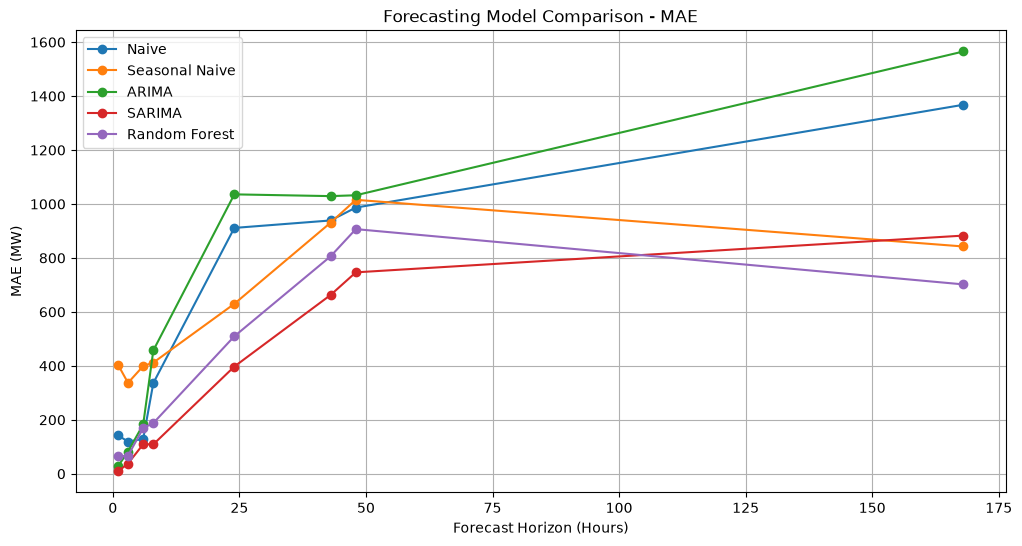

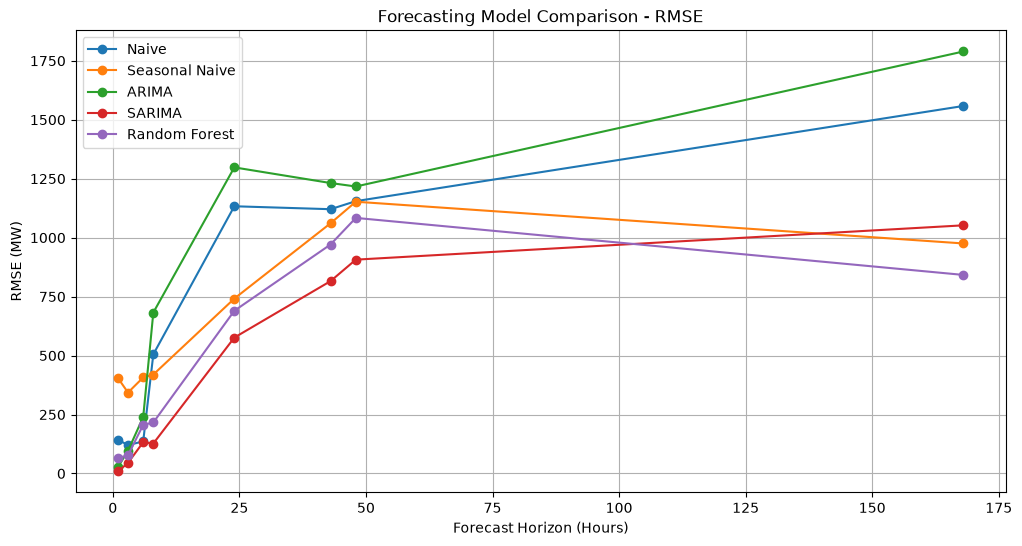

In [48]:
plt.figure(figsize=(12, 6))

for model_name in all_results["Model"].unique():

    model_data = all_results[
        all_results["Model"] == model_name
    ]

    plt.plot(
        model_data["Horizon"],
        model_data["MAE"],
        marker="o",
        label=model_name
    )

plt.xlabel("Forecast Horizon (Hours)")
plt.ylabel("MAE (MW)")
plt.title("Forecasting Model Comparison - MAE")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 6))

for model_name in all_results["Model"].unique():

    model_data = all_results[
        all_results["Model"] == model_name
    ]

    plt.plot(
        model_data["Horizon"],
        model_data["RMSE"],
        marker="o",
        label=model_name
    )

plt.xlabel("Forecast Horizon (Hours)")
plt.ylabel("RMSE (MW)")
plt.title("Forecasting Model Comparison - RMSE")
plt.legend()
plt.grid(True)
plt.show()

### 3.6 XGBoost Regressor

XGBoost is an ensemble machine learning algorithm based on
gradient boosting.

It builds decision trees sequentially to reduce prediction
errors.

We will use calendar features, lag features, and rolling
statistical features for electricity demand forecasting.

Multi-step forecasting will be performed recursively to
prevent future actual values from leaking into predictions.

In [49]:
from xgboost import XGBRegressor
xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

print("XGBoost model trained successfully.")

XGBoost model trained successfully.


In [50]:
def xgboost_forecast(history, last_datetime, horizon, model):

    values = list(history)

    predictions = []

    future_dates = pd.date_range(
        start=last_datetime + pd.Timedelta(hours=1),
        periods=horizon,
        freq="h"
    )

    for future_date in future_dates:

        # Calendar features
        hour = future_date.hour
        day_of_week = future_date.day_of_week
        day = future_date.day
        month = future_date.month
        year = future_date.year
        is_weekend = int(day_of_week >= 5)

        # Cyclical features
        hour_sin = np.sin(2 * np.pi * hour / 24)
        hour_cos = np.cos(2 * np.pi * hour / 24)

        month_sin = np.sin(2 * np.pi * month / 12)
        month_cos = np.cos(2 * np.pi * month / 12)

        # Lag features
        lag_1 = values[-1]
        lag_24 = values[-24]
        lag_168 = values[-168]

        # Rolling features
        rolling_mean_24 = np.mean(values[-24:])
        rolling_mean_168 = np.mean(values[-168:])
        rolling_std_24 = np.std(values[-24:], ddof=1)

        # Create feature row
        feature_row = pd.DataFrame([{
            "Hour": hour,
            "DayOfWeek": day_of_week,
            "Day": day,
            "Month": month,
            "Year": year,
            "IsWeekend": is_weekend,
            "Hour_sin": hour_sin,
            "Hour_cos": hour_cos,
            "Month_sin": month_sin,
            "Month_cos": month_cos,
            "Lag_1": lag_1,
            "Lag_24": lag_24,
            "Lag_168": lag_168,
            "Rolling_Mean_24": rolling_mean_24,
            "Rolling_Mean_168": rolling_mean_168,
            "Rolling_Std_24": rolling_std_24
        }])

        # Keep the same feature order used during training
        feature_row = feature_row[feature_cols]

        # Predict
        prediction = model.predict(feature_row)[0]

        predictions.append(prediction)

        # Use prediction for the next forecast step
        values.append(prediction)

    return np.array(predictions)

In [51]:
xgb_test = xgboost_forecast(
    history=history,
    last_datetime=train.index[-1],
    horizon=43,
    model=xgb_model
)

print("Forecast length:", len(xgb_test))

print("\nFirst 5 predictions:")
print(xgb_test[:5])

Forecast length: 43

First 5 predictions:
[6402.0557 6371.8047 6315.3784 6239.326  6167.455 ]


In [52]:
max_horizon = max(evaluation_horizons)

xgb_predictions = xgboost_forecast(
    history=history,
    last_datetime=train.index[-1],
    horizon=max_horizon,
    model=xgb_model
)

xgb_results = []

for horizon in evaluation_horizons:

    actual = actual_values[:horizon]

    predicted = xgb_predictions[:horizon]

    mae, rmse, mape = calculate_metrics(actual, predicted)

    xgb_results.append({
        "Model": "XGBoost",
        "Horizon": horizon,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    })

xgb_results = pd.DataFrame(xgb_results)

xgb_results

,Model,Horizon,MAE,RMSE,MAPE
0,XGBoost,1,86.944336,86.944336,1.339873
1,XGBoost,3,101.920410,103.320643,1.577251
2,XGBoost,6,178.094482,200.035038,2.785981
3,XGBoost,8,177.399780,195.200819,2.912015
4,XGBoost,24,435.706258,626.272507,6.703669
5,XGBoost,43,732.083723,904.415403,11.225968
6,XGBoost,48,835.687815,1022.275875,12.376914
7,XGBoost,168,516.311609,696.164947,8.778781


In [53]:
all_results = pd.concat(
    [
        baseline_results,
        arima_results,
        sarima_results,
        rf_results,
        xgb_results
    ],
    ignore_index=True
)

all_results

,Model,Horizon,MAE,RMSE,MAPE
0,Naive,1,143.000000,143.000000,2.203729
1,Seasonal Naive,1,405.000000,405.000000,6.241331
2,Naive,3,119.000000,120.602653,1.839779
3,Seasonal Naive,3,337.000000,343.152541,5.211800
4,Naive,6,129.166667,135.797030,2.021233
5,Seasonal Naive,6,399.166667,407.191806,6.242191
6,Naive,8,336.250000,505.379808,6.008541
7,Seasonal Naive,8,412.000000,419.531286,6.786922
8,Naive,24,911.291667,1133.091917,17.333665
9,Seasonal Naive,24,629.958333,741.563691,10.225412


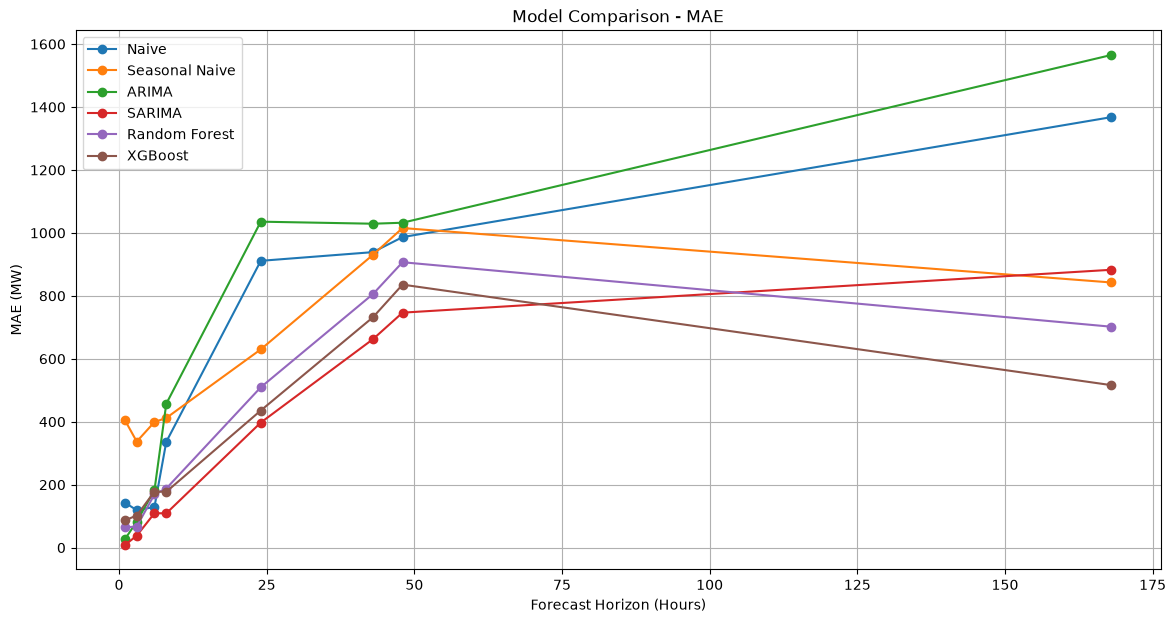

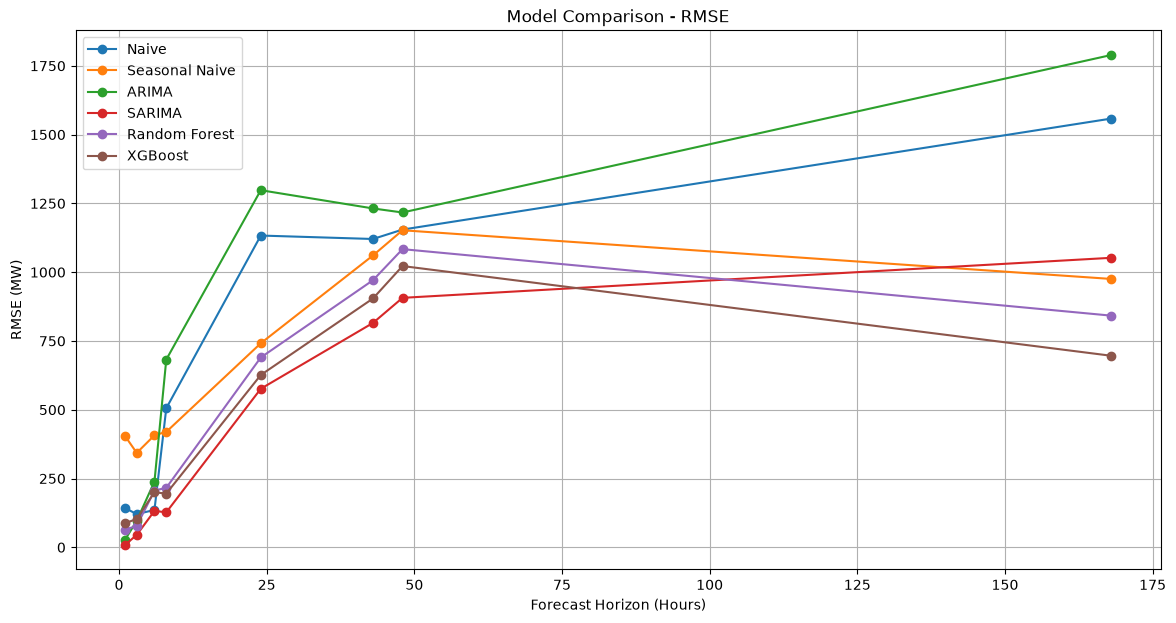

In [54]:
plt.figure(figsize=(14, 7))

for model_name in all_results["Model"].unique():

    model_data = all_results[
        all_results["Model"] == model_name
    ]

    plt.plot(
        model_data["Horizon"],
        model_data["MAE"],
        marker="o",
        label=model_name
    )

plt.xlabel("Forecast Horizon (Hours)")
plt.ylabel("MAE (MW)")
plt.title("Model Comparison - MAE")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(14, 7))

for model_name in all_results["Model"].unique():

    model_data = all_results[
        all_results["Model"] == model_name
    ]

    plt.plot(
        model_data["Horizon"],
        model_data["RMSE"],
        marker="o",
        label=model_name
    )

plt.xlabel("Forecast Horizon (Hours)")
plt.ylabel("RMSE (MW)")
plt.title("Model Comparison - RMSE")
plt.legend()
plt.grid(True)
plt.show()

### 3.7 LSTM (Long Short-Term Memory)

LSTM is a recurrent neural network designed for sequential
data and time-series forecasting.

It can learn temporal patterns and dependencies from historical
electricity demand.

For this implementation, we will use the previous 168 hours
(one week) of electricity demand to predict the next hour.

Multi-step forecasting will be performed recursively so the
model can forecast any positive number of future hours.

In [55]:
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

In [56]:
scaler = MinMaxScaler(feature_range=(0, 1))
train_values = train["PJMW_MW"].values.reshape(-1, 1)
scaled_train = scaler.fit_transform(train_values)

print("Scaled training data shape:", scaled_train.shape)

Scaled training data shape: (100144, 1)


In [57]:
sequence_length = 168

X_lstm = []
y_lstm = []

for i in range(sequence_length, len(scaled_train)):

    X_lstm.append(scaled_train[i-sequence_length:i, 0])

    y_lstm.append(scaled_train[i, 0])

X_lstm = np.array(X_lstm)
y_lstm = np.array(y_lstm)

# Reshape for LSTM
X_lstm = X_lstm.reshape(
    X_lstm.shape[0],
    X_lstm.shape[1],
    1
)

print("X shape:", X_lstm.shape)
print("y shape:", y_lstm.shape)

X shape: (99976, 168, 1)
y shape: (99976,)


In [58]:
lstm_model = Sequential([

    LSTM(
        64,
        return_sequences=True,
        input_shape=(sequence_length, 1)
    ),

    Dropout(0.2),

    LSTM(32),

    Dropout(0.2),

    Dense(16, activation="relu"),

    Dense(1)
])

lstm_model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

lstm_model.summary()

c:\Users\SHIVAM\Desktop\New_Projects\Forecast\.venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 168, 64)        │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 168, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,857 (116.63 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

In [59]:
early_stopping = EarlyStopping( monitor="val_loss", patience=3, restore_best_weights=True)

history_lstm = lstm_model.fit(
    X_lstm,
    y_lstm,
    epochs=15,
    batch_size=128,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/15
703/703 ━━━━━━━━━━━━━━━━━━━━ 82s 114ms/step - loss: 0.0101 - val_loss: 0.0041
Epoch 2/15
703/703 ━━━━━━━━━━━━━━━━━━━━ 89s 126ms/step - loss: 0.0053 - val_loss: 0.0050
Epoch 3/15
703/703 ━━━━━━━━━━━━━━━━━━━━ 99s 140ms/step - loss: 0.0046 - val_loss: 0.0025
Epoch 4/15
703/703 ━━━━━━━━━━━━━━━━━━━━ 101s 144ms/step - loss: 0.0020 - val_loss: 0.0012
Epoch 5/15
703/703 ━━━━━━━━━━━━━━━━━━━━ 111s 158ms/step - loss: 8.4522e-04 - val_loss: 7.1454e-04
Epoch 6/15
703/703 ━━━━━━━━━━━━━━━━━━━━ 96s 136ms/step - loss: 5.1467e-04 - val_loss: 8.8562e-04
Epoch 7/15
703/703 ━━━━━━━━━━━━━━━━━━━━ 94s 133ms/step - loss: 4.2632e-04 - val_loss: 6.6596e-04
Epoch 8/15
703/703 ━━━━━━━━━━━━━━━━━━━━ 94s 133ms/step - loss: 3.7418e-04 - val_loss: 7.3948e-04
Epoch 9/15
703/703 ━━━━━━━━━━━━━━━━━━━━ 1203s 2s/step - loss: 3.3010e-04 - val_loss: 0.0010
Epoch 10/15
703/703 ━━━━━━━━━━━━━━━━━━━━ 81s 115ms/step - loss: 2.9449e-04 - val_loss: 0.0011


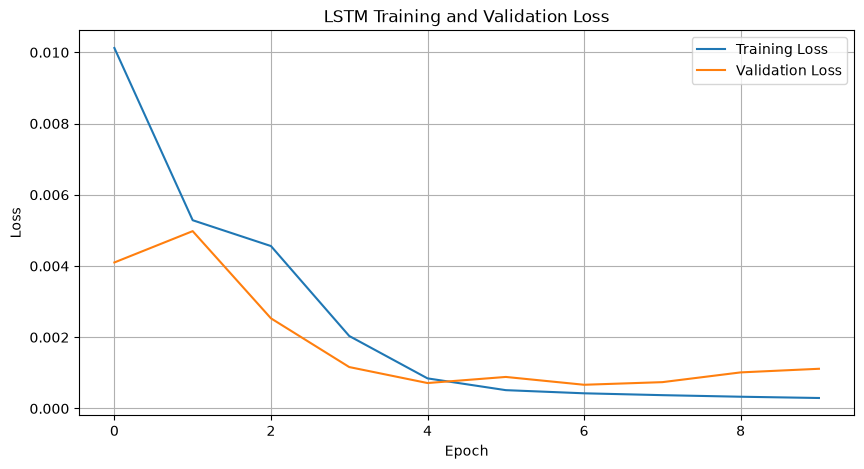

In [60]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_lstm.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_lstm.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LSTM Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.show()

In [61]:
def lstm_forecast(history, horizon, model, scaler, sequence_length=168):

    # Convert historical values to a 2D array
    history = np.array(history).reshape(-1, 1)

    # Scale historical values
    scaled_values = scaler.transform(history)

    # Store predictions
    predictions = []

    # Use the most recent sequence
    current_sequence = scaled_values[-sequence_length:].copy()

    for i in range(horizon):

        # Reshape for LSTM input
        X_input = current_sequence.reshape(1, sequence_length, 1)

        # Predict next hour
        prediction_scaled = model.predict(
            X_input,
            verbose=0
        )[0][0]

        # Convert prediction back to original MW scale
        prediction = scaler.inverse_transform(
            np.array([[prediction_scaled]])
        )[0][0]

        predictions.append(prediction)

        # Add scaled prediction to the sequence
        current_sequence = np.append(
            current_sequence[1:],
            [[prediction_scaled]],
            axis=0
        )

    return np.array(predictions)

In [62]:
lstm_test = lstm_forecast(
    history=history,
    horizon=43,
    model=lstm_model,
    scaler=scaler
)

print("Forecast length:", len(lstm_test))

print("\nFirst 5 predictions:")
print(lstm_test[:5])

Forecast length: 43

First 5 predictions:
[6286.86   6192.2046 5991.0117 5696.8164 5324.68  ]


In [63]:
max_horizon = max(evaluation_horizons)

lstm_predictions = lstm_forecast(
    history=history,
    horizon=max_horizon,
    model=lstm_model,
    scaler=scaler
)

lstm_results = []

for horizon in evaluation_horizons:

    actual = actual_values[:horizon]

    predicted = lstm_predictions[:horizon]

    mae, rmse, mape = calculate_metrics(actual, predicted)

    lstm_results.append({
        "Model": "LSTM",
        "Horizon": horizon,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    })

lstm_results = pd.DataFrame(lstm_results)

lstm_results

,Model,Horizon,MAE,RMSE,MAPE
0,LSTM,1,202.140137,202.140137,3.115120
1,LSTM,3,308.307943,325.457332,4.773668
2,LSTM,6,678.464762,794.419025,10.655426
3,LSTM,8,782.719971,879.609421,13.075441
4,LSTM,24,1181.243835,1327.060456,19.650586
5,LSTM,43,1642.662064,1825.687416,26.172445
6,LSTM,48,1755.203074,1939.148597,27.106987
7,LSTM,168,1159.295455,1453.205425,19.670791


In [64]:
all_results = pd.concat(
    [
        baseline_results,
        arima_results,
        sarima_results,
        rf_results,
        xgb_results,
        lstm_results
    ],
    ignore_index=True
)

all_results

,Model,Horizon,MAE,RMSE,MAPE
0,Naive,1,143.000000,143.000000,2.203729
1,Seasonal Naive,1,405.000000,405.000000,6.241331
2,Naive,3,119.000000,120.602653,1.839779
3,Seasonal Naive,3,337.000000,343.152541,5.211800
4,Naive,6,129.166667,135.797030,2.021233
5,Seasonal Naive,6,399.166667,407.191806,6.242191
6,Naive,8,336.250000,505.379808,6.008541
7,Seasonal Naive,8,412.000000,419.531286,6.786922
8,Naive,24,911.291667,1133.091917,17.333665
9,Seasonal Naive,24,629.958333,741.563691,10.225412


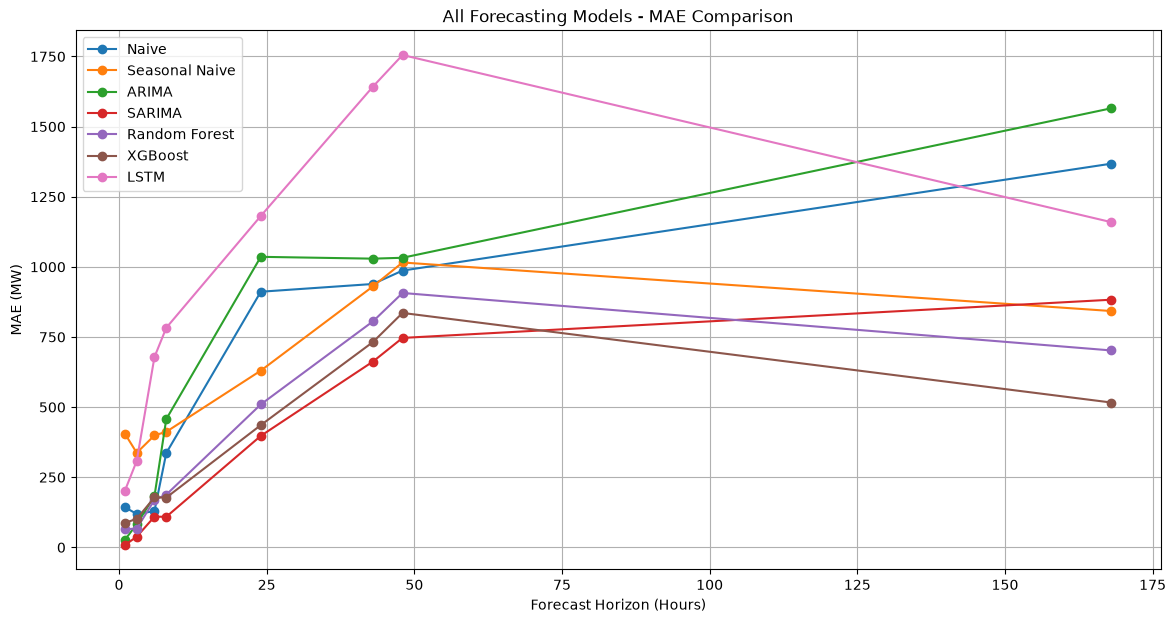

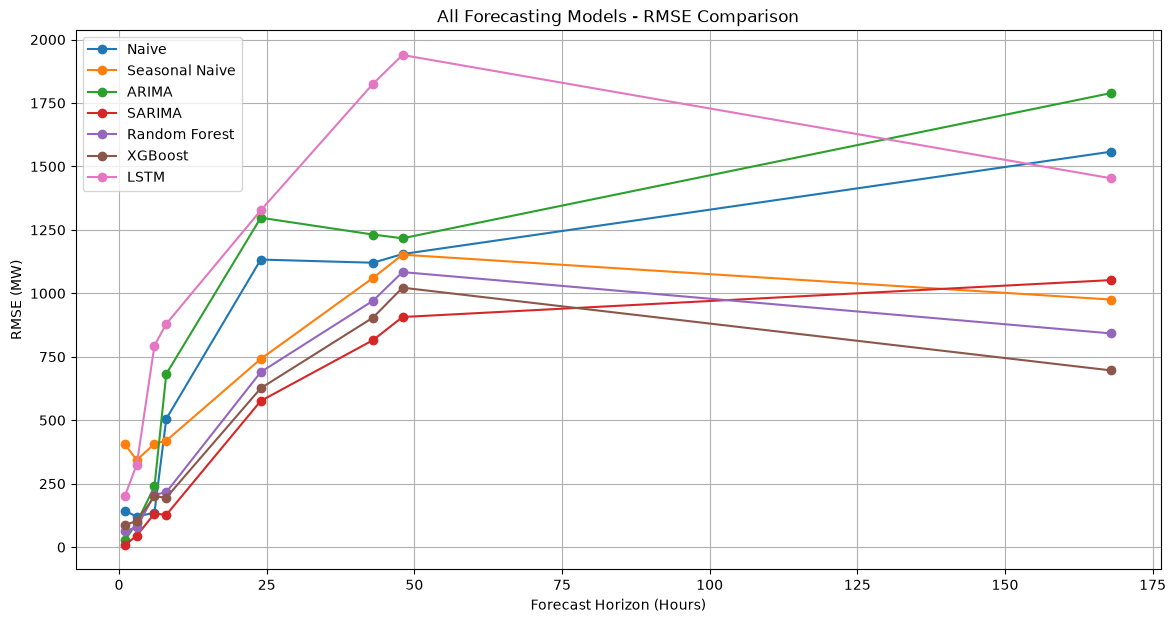

In [66]:
plt.figure(figsize=(14, 7))

for model_name in all_results["Model"].unique():

    model_data = all_results[
        all_results["Model"] == model_name
    ]

    plt.plot(
        model_data["Horizon"],
        model_data["MAE"],
        marker="o",
        label=model_name
    )

plt.xlabel("Forecast Horizon (Hours)")
plt.ylabel("MAE (MW)")
plt.title("All Forecasting Models - MAE Comparison")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(14, 7))

for model_name in all_results["Model"].unique():

    model_data = all_results[
        all_results["Model"] == model_name
    ]

    plt.plot(
        model_data["Horizon"],
        model_data["RMSE"],
        marker="o",
        label=model_name
    )

plt.xlabel("Forecast Horizon (Hours)")
plt.ylabel("RMSE (MW)")
plt.title("All Forecasting Models - RMSE Comparison")
plt.legend()
plt.grid(True)
plt.show()

# Stage 4: Hyperparameter Tuning

Hyperparameter tuning is performed to improve model performance
by testing different model configurations.

The models will be tuned using the validation dataset.
The test dataset will remain untouched until final evaluation.

### 4.1 SARIMA Hyperparameter Tuning

We will experiment with different ARIMA and seasonal parameters
to identify the best SARIMA configuration.

In [67]:
sarima_configs = [
    ((1, 1, 1), (1, 1, 1, 24)),
    ((1, 1, 1), (0, 1, 1, 24)),
    ((1, 1, 1), (1, 1, 0, 24)),
    ((2, 1, 1), (1, 1, 1, 24)),
    ((1, 1, 2), (1, 1, 1, 24)),
    ((2, 1, 2), (0, 1, 1, 24))
]

print("Number of configurations:", len(sarima_configs))

Number of configurations: 6


In [68]:
import warnings

warnings.filterwarnings("ignore")

sarima_tuning_results = []

recent_history = history[-8760:]

max_horizon = max(evaluation_horizons)

for order, seasonal_order in sarima_configs:

    print(f"Testing SARIMA{order}{seasonal_order}")

    try:

        model = SARIMAX(
            recent_history,
            order=order,
            seasonal_order=seasonal_order,
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        model_fit = model.fit(disp=False)

        predictions = model_fit.forecast(
            steps=max_horizon
        )

        horizon_maes = []

        for horizon in evaluation_horizons:

            actual = actual_values[:horizon]

            predicted = predictions[:horizon]

            mae = mean_absolute_error(
                actual,
                predicted
            )

            horizon_maes.append(mae)

        average_mae = np.mean(horizon_maes)

        mae_168 = mean_absolute_error(
            actual_values[:168],
            predictions[:168]
        )

        sarima_tuning_results.append({
            "Order": order,
            "Seasonal Order": seasonal_order,
            "Average MAE": average_mae,
            "MAE 168 Hours": mae_168
        })

    except Exception as e:

        print("Configuration failed:", e)

Testing SARIMA(1, 1, 1)(1, 1, 1, 24)
Testing SARIMA(1, 1, 1)(0, 1, 1, 24)
Testing SARIMA(1, 1, 1)(1, 1, 0, 24)
Testing SARIMA(2, 1, 1)(1, 1, 1, 24)
Testing SARIMA(1, 1, 2)(1, 1, 1, 24)
Testing SARIMA(2, 1, 2)(0, 1, 1, 24)


In [69]:
sarima_tuning_df = pd.DataFrame(
    sarima_tuning_results
)

sarima_tuning_df = sarima_tuning_df.sort_values(
    by="Average MAE",
    ascending=True
).reset_index(drop=True)

sarima_tuning_df

,Order,Seasonal Order,Average MAE,MAE 168 Hours
0,"(2, 1, 1)","(1, 1, 1, 24)",368.973488,883.066295
1,"(1, 1, 1)","(1, 1, 1, 24)",369.251057,882.823931
2,"(1, 1, 2)","(1, 1, 1, 24)",370.492291,881.862733
3,"(1, 1, 1)","(0, 1, 1, 24)",387.350977,876.053275
4,"(1, 1, 1)","(1, 1, 0, 24)",403.253027,2097.318154
5,"(2, 1, 2)","(0, 1, 1, 24)",420.193308,820.250778


In [70]:
best_sarima_order = sarima_tuning_df.loc[0, "Order"]

best_sarima_seasonal_order = sarima_tuning_df.loc[
    0, "Seasonal Order"
]

print("Best SARIMA order:", best_sarima_order)

print(
    "Best seasonal order:",
    best_sarima_seasonal_order
)

Best SARIMA order: (2, 1, 1)
Best seasonal order: (1, 1, 1, 24)


In [71]:
best_sarima_model = SARIMAX(
    recent_history,
    order=best_sarima_order,
    seasonal_order=best_sarima_seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False
)

best_sarima_fit = best_sarima_model.fit(disp=False)

best_sarima_predictions = best_sarima_fit.forecast(
    steps=max(evaluation_horizons)
)

print("Tuned SARIMA model trained successfully.")

Tuned SARIMA model trained successfully.


In [73]:
tuned_sarima_results = []

for horizon in evaluation_horizons:

    actual = actual_values[:horizon]

    predicted = best_sarima_predictions[:horizon]

    mae, rmse, mape = calculate_metrics(
        actual,
        predicted
    )

    tuned_sarima_results.append({
        "Model": "Tuned SARIMA",
        "Horizon": horizon,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    })

tuned_sarima_results = pd.DataFrame(
    tuned_sarima_results
)

tuned_sarima_results

,Model,Horizon,MAE,RMSE,MAPE
0,Tuned SARIMA,1,7.267581,7.267581,0.111998
1,Tuned SARIMA,3,37.760396,45.538738,0.584636
2,Tuned SARIMA,6,109.069434,132.138208,1.711131
3,Tuned SARIMA,8,108.678794,126.894480,1.787138
4,Tuned SARIMA,24,397.224927,576.165004,6.106284
5,Tuned SARIMA,43,662.274942,815.398908,10.153352
6,Tuned SARIMA,48,746.445534,906.579307,11.073720
7,Tuned SARIMA,168,883.066295,1052.532624,17.552933


In [74]:
sarima_comparison = pd.concat(
    [
        sarima_results,
        tuned_sarima_results
    ],
    ignore_index=True
)

sarima_comparison

,Model,Horizon,MAE,RMSE,MAPE
0,SARIMA,1,8.399107,8.399107,0.129436
1,SARIMA,3,37.976276,45.113964,0.587973
2,SARIMA,6,109.417616,132.387925,1.716548
3,SARIMA,8,108.962259,127.106842,1.791608
4,SARIMA,24,397.356828,576.183739,6.108596
5,SARIMA,43,662.457424,815.548273,10.156347
6,SARIMA,48,746.615015,906.709216,11.076480
7,SARIMA,168,882.823931,1052.224911,17.546803
8,Tuned SARIMA,1,7.267581,7.267581,0.111998
9,Tuned SARIMA,3,37.760396,45.538738,0.584636


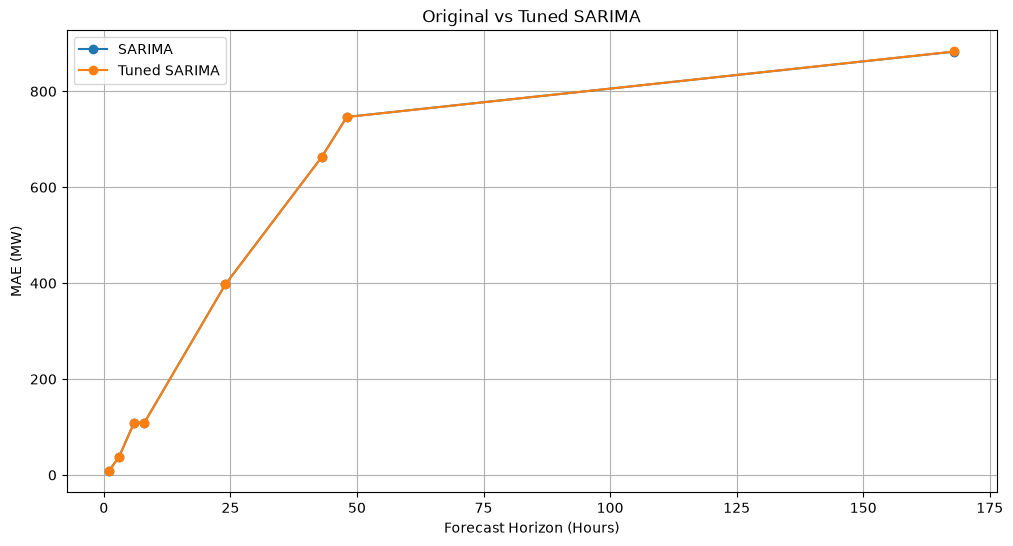

In [75]:
plt.figure(figsize=(12, 6))

for model_name in sarima_comparison["Model"].unique():

    model_data = sarima_comparison[
        sarima_comparison["Model"] == model_name
    ]

    plt.plot(
        model_data["Horizon"],
        model_data["MAE"],
        marker="o",
        label=model_name
    )

plt.xlabel("Forecast Horizon (Hours)")
plt.ylabel("MAE (MW)")
plt.title("Original vs Tuned SARIMA")
plt.legend()
plt.grid(True)

plt.show()

### 4.2 XGBoost Hyperparameter Tuning

XGBoost hyperparameters are tuned to improve forecasting
performance.

Different combinations of the number of trees, learning rate,
tree depth, and sampling parameters will be tested.

The configurations will be evaluated using the validation dataset.

In [76]:
xgb_configs = [
    {
        "n_estimators": 200,
        "learning_rate": 0.05,
        "max_depth": 4,
        "subsample": 0.8,
        "colsample_bytree": 0.8
    },
    {
        "n_estimators": 300,
        "learning_rate": 0.05,
        "max_depth": 6,
        "subsample": 0.8,
        "colsample_bytree": 0.8
    },
    {
        "n_estimators": 500,
        "learning_rate": 0.05,
        "max_depth": 6,
        "subsample": 0.8,
        "colsample_bytree": 0.8
    },
    {
        "n_estimators": 300,
        "learning_rate": 0.03,
        "max_depth": 6,
        "subsample": 0.8,
        "colsample_bytree": 0.8
    },
    {
        "n_estimators": 300,
        "learning_rate": 0.05,
        "max_depth": 8,
        "subsample": 0.8,
        "colsample_bytree": 0.8
    },
    {
        "n_estimators": 300,
        "learning_rate": 0.05,
        "max_depth": 6,
        "subsample": 1.0,
        "colsample_bytree": 1.0
    }
]

print("Number of XGBoost configurations:", len(xgb_configs))

Number of XGBoost configurations: 6


In [77]:
xgb_tuning_results = []

max_horizon = max(evaluation_horizons)

for config in xgb_configs:

    print("Testing configuration:", config)

    try:

        model = XGBRegressor(
            **config,
            objective="reg:squarederror",
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_train, y_train)

        predictions = xgboost_forecast(
            history=history,
            last_datetime=train.index[-1],
            horizon=max_horizon,
            model=model
        )

        horizon_maes = []

        for horizon in evaluation_horizons:

            actual = actual_values[:horizon]

            predicted = predictions[:horizon]

            mae = mean_absolute_error(
                actual,
                predicted
            )

            horizon_maes.append(mae)

        average_mae = np.mean(horizon_maes)

        mae_168 = mean_absolute_error(
            actual_values[:168],
            predictions[:168]
        )

        xgb_tuning_results.append({
            "Configuration": config,
            "Average MAE": average_mae,
            "MAE 168 Hours": mae_168
        })

    except Exception as e:

        print("Configuration failed:", e)

Testing configuration: {'n_estimators': 200, 'learning_rate': 0.05, 'max_depth': 4, 'subsample': 0.8, 'colsample_bytree': 0.8}
Testing configuration: {'n_estimators': 300, 'learning_rate': 0.05, 'max_depth': 6, 'subsample': 0.8, 'colsample_bytree': 0.8}
Testing configuration: {'n_estimators': 500, 'learning_rate': 0.05, 'max_depth': 6, 'subsample': 0.8, 'colsample_bytree': 0.8}
Testing configuration: {'n_estimators': 300, 'learning_rate': 0.03, 'max_depth': 6, 'subsample': 0.8, 'colsample_bytree': 0.8}
Testing configuration: {'n_estimators': 300, 'learning_rate': 0.05, 'max_depth': 8, 'subsample': 0.8, 'colsample_bytree': 0.8}
Testing configuration: {'n_estimators': 300, 'learning_rate': 0.05, 'max_depth': 6, 'subsample': 1.0, 'colsample_bytree': 1.0}


In [78]:
xgb_tuning_df = pd.DataFrame(
    xgb_tuning_results
)

xgb_tuning_df = xgb_tuning_df.sort_values(
    by="Average MAE",
    ascending=True
).reset_index(drop=True)

xgb_tuning_df

,Configuration,Average MAE,MAE 168 Hours
0,"{'n_estimators': 200, 'learning_rate': 0.05, '...",316.777479,523.232317
1,"{'n_estimators': 300, 'learning_rate': 0.03, '...",318.648420,516.861488
2,"{'n_estimators': 300, 'learning_rate': 0.05, '...",348.825949,521.880293
3,"{'n_estimators': 300, 'learning_rate': 0.05, '...",354.227439,542.588446
4,"{'n_estimators': 500, 'learning_rate': 0.05, '...",369.416509,479.831887
5,"{'n_estimators': 300, 'learning_rate': 0.05, '...",383.018552,516.311609


In [79]:
best_xgb_config = xgb_tuning_df.loc[
    0, "Configuration"
]

print("Best XGBoost configuration:")
print(best_xgb_config)

Best XGBoost configuration:
{'n_estimators': 200, 'learning_rate': 0.05, 'max_depth': 4, 'subsample': 0.8, 'colsample_bytree': 0.8}


In [80]:
best_xgb_model = XGBRegressor(
    **best_xgb_config,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

best_xgb_model.fit(
    X_train,
    y_train
)

print("Tuned XGBoost model trained successfully.")

Tuned XGBoost model trained successfully.


In [81]:
best_xgb_predictions = xgboost_forecast(
    history=history,
    last_datetime=train.index[-1],
    horizon=max(evaluation_horizons),
    model=best_xgb_model
)

tuned_xgb_results = []

for horizon in evaluation_horizons:

    actual = actual_values[:horizon]

    predicted = best_xgb_predictions[:horizon]

    mae, rmse, mape = calculate_metrics(
        actual,
        predicted
    )

    tuned_xgb_results.append({
        "Model": "Tuned XGBoost",
        "Horizon": horizon,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    })

tuned_xgb_results = pd.DataFrame(
    tuned_xgb_results
)

tuned_xgb_results

,Model,Horizon,MAE,RMSE,MAPE
0,Tuned XGBoost,1,48.540527,48.540527,0.748043
1,Tuned XGBoost,3,55.926595,56.844831,0.865492
2,Tuned XGBoost,6,55.540690,69.417938,0.860536
3,Tuned XGBoost,8,67.831360,81.148538,1.126181
4,Tuned XGBoost,24,374.344279,638.775969,5.495251
5,Tuned XGBoost,43,644.965809,856.983919,9.640602
6,Tuned XGBoost,48,763.838257,996.669516,11.034436
7,Tuned XGBoost,168,523.232317,701.158344,9.051662


In [82]:
xgb_comparison = pd.concat(
    [
        xgb_results,
        tuned_xgb_results
    ],
    ignore_index=True
)

xgb_comparison

,Model,Horizon,MAE,RMSE,MAPE
0,XGBoost,1,86.944336,86.944336,1.339873
1,XGBoost,3,101.920410,103.320643,1.577251
2,XGBoost,6,178.094482,200.035038,2.785981
3,XGBoost,8,177.399780,195.200819,2.912015
4,XGBoost,24,435.706258,626.272507,6.703669
5,XGBoost,43,732.083723,904.415403,11.225968
6,XGBoost,48,835.687815,1022.275875,12.376914
7,XGBoost,168,516.311609,696.164947,8.778781
8,Tuned XGBoost,1,48.540527,48.540527,0.748043
9,Tuned XGBoost,3,55.926595,56.844831,0.865492


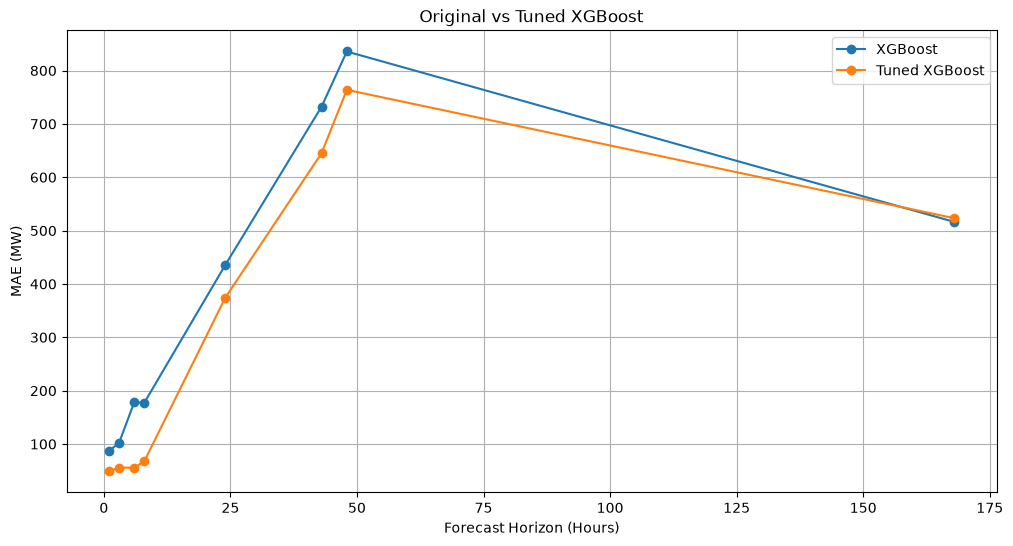

In [83]:
plt.figure(figsize=(12, 6))

for model_name in xgb_comparison["Model"].unique():

    model_data = xgb_comparison[
        xgb_comparison["Model"] == model_name
    ]

    plt.plot(
        model_data["Horizon"],
        model_data["MAE"],
        marker="o",
        label=model_name
    )

plt.xlabel("Forecast Horizon (Hours)")
plt.ylabel("MAE (MW)")
plt.title("Original vs Tuned XGBoost")
plt.legend()
plt.grid(True)

plt.show()

### 4.3 Random Forest Hyperparameter Tuning

Random Forest hyperparameters are tuned to improve forecasting
performance.

Different combinations of the number of trees, tree depth,
minimum samples per leaf, and feature sampling will be tested.

The configurations will be evaluated using the validation dataset.

In [84]:
rf_configs = [
    {
        "n_estimators": 100,
        "max_depth": None,
        "min_samples_leaf": 1,
        "max_features": 1.0
    },
    {
        "n_estimators": 200,
        "max_depth": None,
        "min_samples_leaf": 1,
        "max_features": 1.0
    },
    {
        "n_estimators": 100,
        "max_depth": 20,
        "min_samples_leaf": 1,
        "max_features": 1.0
    },
    {
        "n_estimators": 100,
        "max_depth": 30,
        "min_samples_leaf": 2,
        "max_features": 0.8
    },
    {
        "n_estimators": 200,
        "max_depth": 20,
        "min_samples_leaf": 2,
        "max_features": 0.8
    },
    {
        "n_estimators": 100,
        "max_depth": None,
        "min_samples_leaf": 2,
        "max_features": "sqrt"
    }
]

print("Number of Random Forest configurations:", len(rf_configs))

Number of Random Forest configurations: 6


In [85]:
rf_tuning_results = []

max_horizon = max(evaluation_horizons)

for config in rf_configs:

    print("Testing configuration:", config)

    try:

        model = RandomForestRegressor(
            **config,
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_train, y_train)

        predictions = random_forest_forecast(
            history=history,
            last_datetime=train.index[-1],
            horizon=max_horizon,
            model=model
        )

        horizon_maes = []

        for horizon in evaluation_horizons:

            actual = actual_values[:horizon]

            predicted = predictions[:horizon]

            mae = mean_absolute_error(
                actual,
                predicted
            )

            horizon_maes.append(mae)

        average_mae = np.mean(horizon_maes)

        mae_168 = mean_absolute_error(
            actual_values[:168],
            predictions[:168]
        )

        rf_tuning_results.append({
            "Configuration": config,
            "Average MAE": average_mae,
            "MAE 168 Hours": mae_168
        })

    except Exception as e:

        print("Configuration failed:", e)

Testing configuration: {'n_estimators': 100, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 1.0}
Testing configuration: {'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 1.0}
Testing configuration: {'n_estimators': 100, 'max_depth': 20, 'min_samples_leaf': 1, 'max_features': 1.0}
Testing configuration: {'n_estimators': 100, 'max_depth': 30, 'min_samples_leaf': 2, 'max_features': 0.8}
Testing configuration: {'n_estimators': 200, 'max_depth': 20, 'min_samples_leaf': 2, 'max_features': 0.8}
Testing configuration: {'n_estimators': 100, 'max_depth': None, 'min_samples_leaf': 2, 'max_features': 'sqrt'}


In [86]:
rf_tuning_df = pd.DataFrame(
    rf_tuning_results
)

rf_tuning_df = rf_tuning_df.sort_values(
    by="Average MAE",
    ascending=True
).reset_index(drop=True)

rf_tuning_df

,Configuration,Average MAE,MAE 168 Hours
0,"{'n_estimators': 100, 'max_depth': None, 'min_...",352.571705,590.649891
1,"{'n_estimators': 100, 'max_depth': 30, 'min_sa...",380.775464,676.137133
2,"{'n_estimators': 200, 'max_depth': 20, 'min_sa...",405.884773,749.479892
3,"{'n_estimators': 100, 'max_depth': 20, 'min_sa...",417.666915,738.489281
4,"{'n_estimators': 200, 'max_depth': None, 'min_...",420.710083,725.409702
5,"{'n_estimators': 100, 'max_depth': None, 'min_...",426.585741,701.948929


In [87]:
best_rf_config = rf_tuning_df.loc[
    0, "Configuration"
]

print("Best Random Forest configuration:")
print(best_rf_config)

Best Random Forest configuration:
{'n_estimators': 100, 'max_depth': None, 'min_samples_leaf': 2, 'max_features': 'sqrt'}


In [88]:
best_rf_model = RandomForestRegressor(
    **best_rf_config,
    random_state=42,
    n_jobs=-1
)

best_rf_model.fit(
    X_train,
    y_train
)

print("Tuned Random Forest model trained successfully.")

Tuned Random Forest model trained successfully.


In [89]:
best_rf_predictions = random_forest_forecast(
    history=history,
    last_datetime=train.index[-1],
    horizon=max(evaluation_horizons),
    model=best_rf_model
)

tuned_rf_results = []

for horizon in evaluation_horizons:

    actual = actual_values[:horizon]

    predicted = best_rf_predictions[:horizon]

    mae, rmse, mape = calculate_metrics(
        actual,
        predicted
    )

    tuned_rf_results.append({
        "Model": "Tuned Random Forest",
        "Horizon": horizon,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    })

tuned_rf_results = pd.DataFrame(
    tuned_rf_results
)

tuned_rf_results

,Model,Horizon,MAE,RMSE,MAPE
0,Tuned Random Forest,1,87.736333,87.736333,1.352078
1,Tuned Random Forest,3,72.329925,75.465082,1.118798
2,Tuned Random Forest,6,124.049581,140.868182,1.935319
3,Tuned Random Forest,8,113.787247,129.167424,1.840640
4,Tuned Random Forest,24,389.371428,591.605019,5.895235
5,Tuned Random Forest,43,674.111740,852.542506,10.253008
6,Tuned Random Forest,48,768.537491,955.288994,11.309353
7,Tuned Random Forest,168,590.649891,730.380938,10.717008


In [90]:
rf_comparison = pd.concat(
    [
        rf_results,
        tuned_rf_results
    ],
    ignore_index=True
)

rf_comparison

,Model,Horizon,MAE,RMSE,MAPE
0,Random Forest,1,64.460000,64.460000,0.993373
1,Random Forest,3,67.083333,77.536448,1.038637
2,Random Forest,6,169.260000,206.233038,2.659846
3,Random Forest,8,187.816250,216.207103,3.128393
4,Random Forest,24,509.515417,689.887173,8.041118
5,Random Forest,43,805.767209,970.830692,12.482142
6,Random Forest,48,906.834792,1083.705845,13.569505
7,Random Forest,168,701.948929,841.984049,12.738859
8,Tuned Random Forest,1,87.736333,87.736333,1.352078
9,Tuned Random Forest,3,72.329925,75.465082,1.118798


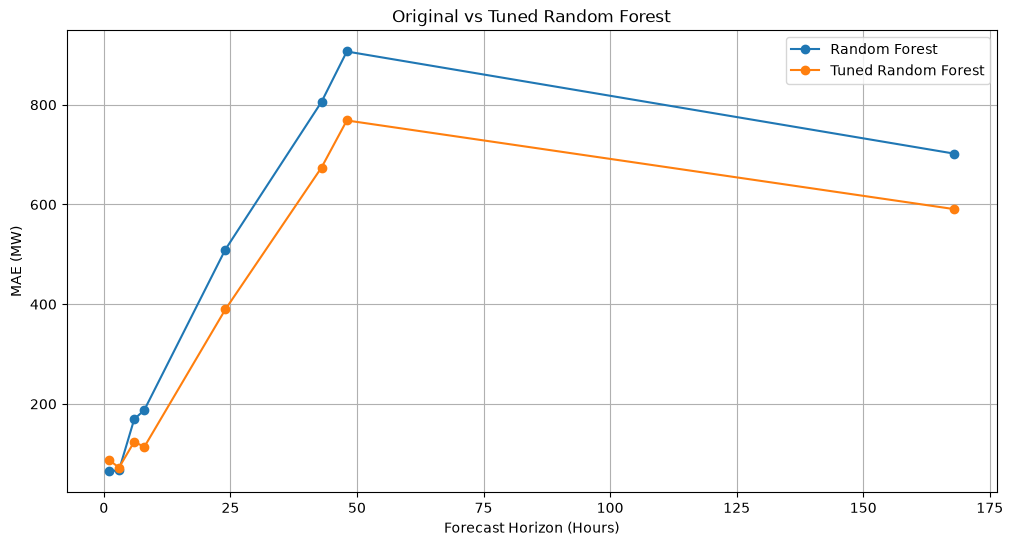

In [91]:
plt.figure(figsize=(12, 6))

for model_name in rf_comparison["Model"].unique():

    model_data = rf_comparison[
        rf_comparison["Model"] == model_name
    ]

    plt.plot(
        model_data["Horizon"],
        model_data["MAE"],
        marker="o",
        label=model_name
    )

plt.xlabel("Forecast Horizon (Hours)")
plt.ylabel("MAE (MW)")
plt.title("Original vs Tuned Random Forest")
plt.legend()
plt.grid(True)

plt.show()

### 4.4 LSTM Hyperparameter Tuning

The LSTM model is tuned using a small number of configurations
because deep learning training is computationally expensive.

Different network architectures will be tested.

The models will be evaluated using the validation dataset.

In [97]:
lstm_configs = [
    {
        "units_1": 32,
        "units_2": 16,
        "dropout": 0.2,
        "batch_size": 256
    },
    {
        "units_1": 64,
        "units_2": 32,
        "dropout": 0.2,
        "batch_size": 128
    }
]

print("Number of LSTM configurations:", len(lstm_configs))

Number of LSTM configurations: 2


In [98]:
lstm_tuning_results = []
lstm_tuned_models = {}

In [99]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dropout, Dense
from tensorflow.keras.callbacks import EarlyStopping

In [100]:
for config_index, config in enumerate(lstm_configs):

    print(f"\nTraining LSTM Configuration {config_index + 1}")

    model = Sequential([
        Input(shape=(sequence_length, 1)),

        LSTM(config["units_1"], return_sequences=True),
        Dropout(config["dropout"]),

        LSTM(config["units_2"]),
        Dropout(config["dropout"]),

        Dense(16, activation="relu"),
        Dense(1)
    ])

    model.compile(
        optimizer="adam",
        loss="mean_squared_error"
    )

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    )

    model.fit(
        X_lstm,
        y_lstm,
        epochs=10,
        batch_size=config["batch_size"],
        validation_split=0.1,
        shuffle=False,
        callbacks=[early_stopping],
        verbose=1
    )

    lstm_tuned_models[config_index] = model

    predictions = lstm_forecast(
        history=history,
        horizon=max(evaluation_horizons),
        model=model,
        scaler=scaler,
        sequence_length=sequence_length
    )

    config_results = []

    for horizon in evaluation_horizons:

        actual = actual_values[:horizon]
        predicted = predictions[:horizon]

        mae, rmse, mape = calculate_metrics(actual, predicted)

        config_results.append({
            "Model": f"LSTM Config {config_index + 1}",
            "Horizon": horizon,
            "MAE": mae,
            "RMSE": rmse,
            "MAPE": mape
        })

    lstm_tuning_results.extend(config_results)


Training LSTM Configuration 1
Epoch 1/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 63s 164ms/step - loss: 0.0232 - val_loss: 0.0103
Epoch 2/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 57s 163ms/step - loss: 0.0103 - val_loss: 0.0089
Epoch 3/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 58s 165ms/step - loss: 0.0057 - val_loss: 0.0043
Epoch 4/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 58s 164ms/step - loss: 0.0035 - val_loss: 0.0040
Epoch 5/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 58s 165ms/step - loss: 0.0029 - val_loss: 0.0042
Epoch 6/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 58s 164ms/step - loss: 0.0026 - val_loss: 0.0046

Training LSTM Configuration 2
Epoch 1/10
703/703 ━━━━━━━━━━━━━━━━━━━━ 274s 387ms/step - loss: 0.0160 - val_loss: 0.0173
Epoch 2/10
703/703 ━━━━━━━━━━━━━━━━━━━━ 128s 183ms/step - loss: 0.0097 - val_loss: 0.0088
Epoch 3/10
703/703 ━━━━━━━━━━━━━━━━━━━━ 118s 168ms/step - loss: 0.0045 - val_loss: 0.0041
Epoch 4/10
703/703 ━━━━━━━━━━━━━━━━━━━━ 104s 147ms/step - loss: 0.0022 - val_loss: 0.0023
Epoch 5/10
703/703 ━━━━━━━━━━━━━━━━━━━━ 109s

In [101]:
lstm_tuning_df = pd.DataFrame(lstm_tuning_results)

lstm_tuning_df

,Model,Horizon,MAE,RMSE,MAPE
0,LSTM Config 1,1,624.435059,624.435059,9.622978
1,LSTM Config 1,3,684.379720,686.733833,10.588626
2,LSTM Config 1,6,878.363688,905.151084,13.730900
3,LSTM Config 1,8,840.638062,865.407385,13.661181
4,LSTM Config 1,24,1029.497284,1198.796733,16.433289
5,LSTM Config 1,43,1444.684990,1648.697989,22.394349
6,LSTM Config 1,48,1582.043955,1798.129967,23.775555
7,LSTM Config 1,168,1012.919095,1319.877024,16.843237
8,LSTM Config 2,1,284.009766,284.009766,4.376788
9,LSTM Config 2,3,434.993652,457.827154,6.735062


In [102]:
lstm_config_comparison = (
    lstm_tuning_df
    .groupby("Model")
    .agg({
        "MAE": "mean",
        "RMSE": "mean",
        "MAPE": "mean"
    })
    .reset_index()
)

lstm_config_comparison = lstm_config_comparison.sort_values(
    by="MAE"
).reset_index(drop=True)

lstm_config_comparison

,Model,MAE,RMSE,MAPE
0,LSTM Config 1,1012.120232,1130.903634,15.881265
1,LSTM Config 2,1242.881196,1366.049069,20.524814


In [103]:
best_lstm_config_name = lstm_config_comparison.loc[0, "Model"]

best_lstm_config_index = int(
    best_lstm_config_name.split()[-1]
) - 1

best_lstm_model = lstm_tuned_models[best_lstm_config_index]

best_lstm_config = lstm_configs[best_lstm_config_index]

print("Best LSTM Configuration:", best_lstm_config_name)
print("Configuration Details:", best_lstm_config)

Best LSTM Configuration: LSTM Config 1
Configuration Details: {'units_1': 32, 'units_2': 16, 'dropout': 0.2, 'batch_size': 256}


In [104]:
best_lstm_predictions = lstm_forecast(
    history=history,
    horizon=max(evaluation_horizons),
    model=best_lstm_model,
    scaler=scaler,
    sequence_length=sequence_length
)

tuned_lstm_results = []

for horizon in evaluation_horizons:

    actual = actual_values[:horizon]
    predicted = best_lstm_predictions[:horizon]

    mae, rmse, mape = calculate_metrics(actual, predicted)

    tuned_lstm_results.append({
        "Model": "Tuned LSTM",
        "Horizon": horizon,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    })

tuned_lstm_results = pd.DataFrame(tuned_lstm_results)

lstm_comparison = pd.concat(
    [lstm_results, tuned_lstm_results],
    ignore_index=True
)

lstm_comparison

,Model,Horizon,MAE,RMSE,MAPE
0,LSTM,1,202.140137,202.140137,3.115120
1,LSTM,3,308.307943,325.457332,4.773668
2,LSTM,6,678.464762,794.419025,10.655426
3,LSTM,8,782.719971,879.609421,13.075441
4,LSTM,24,1181.243835,1327.060456,19.650586
5,LSTM,43,1642.662064,1825.687416,26.172445
6,LSTM,48,1755.203074,1939.148597,27.106987
7,LSTM,168,1159.295455,1453.205425,19.670791
8,Tuned LSTM,1,624.435059,624.435059,9.622978
9,Tuned LSTM,3,684.379720,686.733833,10.588626


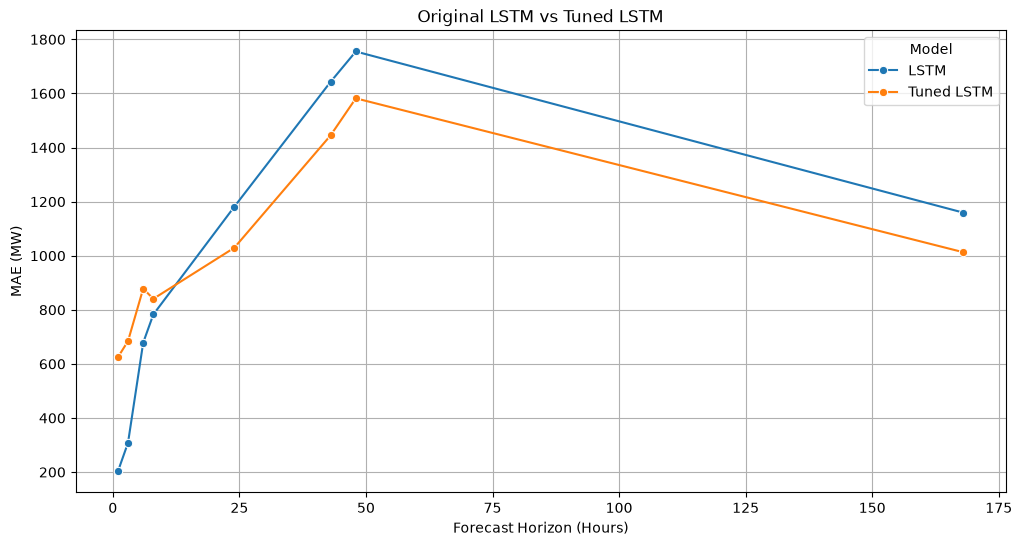

In [105]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=lstm_comparison,
    x="Horizon",
    y="MAE",
    hue="Model",
    marker="o"
)

plt.title("Original LSTM vs Tuned LSTM")
plt.xlabel("Forecast Horizon (Hours)")
plt.ylabel("MAE (MW)")
plt.grid(True)
plt.show()

## 4.5 Overall Model Comparison
All forecasting models, including their tuned versions, are compared across different forecast horizons using MAE, RMSE, and MAPE.

In [106]:
overall_results = pd.concat(
    [
        baseline_results,
        arima_results,
        sarima_results,
        tuned_sarima_results,
        rf_results,
        tuned_rf_results,
        xgb_results,
        tuned_xgb_results,
        lstm_results,
        tuned_lstm_results
    ],
    ignore_index=True
)

overall_results

,Model,Horizon,MAE,RMSE,MAPE
0,Naive,1,143.000000,143.000000,2.203729
1,Seasonal Naive,1,405.000000,405.000000,6.241331
2,Naive,3,119.000000,120.602653,1.839779
3,Seasonal Naive,3,337.000000,343.152541,5.211800
4,Naive,6,129.166667,135.797030,2.021233
...,...,...,...,...,...
83,Tuned LSTM,8,840.638062,865.407385,13.661181
84,Tuned LSTM,24,1029.497284,1198.796733,16.433289
85,Tuned LSTM,43,1444.684990,1648.697989,22.394349
86,Tuned LSTM,48,1582.043955,1798.129967,23.775555


In [107]:
overall_model_comparison = (
    overall_results
    .groupby("Model")
    .agg({
        "MAE": "mean",
        "RMSE": "mean",
        "MAPE": "mean"
    })
    .reset_index()
)

overall_model_comparison = overall_model_comparison.sort_values(
    by="MAE",
    ascending=True
).reset_index(drop=True)

overall_model_comparison

,Model,MAE,RMSE,MAPE
0,Tuned XGBoost,316.777479,431.192448,4.852775
1,Tuned Random Forest,352.571705,445.381810,5.552680
2,Tuned SARIMA,368.973488,457.814356,6.135149
3,SARIMA,369.251057,457.959247,6.139224
4,XGBoost,383.018552,479.328696,5.962556
5,Random Forest,426.585741,518.855543,6.831484
6,Naive,616.509205,733.942108,11.486489
7,Seasonal Naive,621.452416,688.123756,10.067474
8,ARIMA,676.474702,822.568770,12.995041
9,LSTM,963.754655,1093.340976,15.527558


In [108]:
best_model_per_horizon = (
    overall_results
    .sort_values("MAE")
    .groupby("Horizon")
    .first()
    .reset_index()
)

best_model_per_horizon[
    ["Horizon", "Model", "MAE", "RMSE", "MAPE"]
]

,Horizon,Model,MAE,RMSE,MAPE
0,1,Tuned SARIMA,7.267581,7.267581,0.111998
1,3,Tuned SARIMA,37.760396,45.538738,0.584636
2,6,Tuned XGBoost,55.540690,69.417938,0.860536
3,8,Tuned XGBoost,67.831360,81.148538,1.126181
4,24,Tuned XGBoost,374.344279,638.775969,5.495251
5,43,Tuned XGBoost,644.965809,856.983919,9.640602
6,48,Tuned SARIMA,746.445534,906.579307,11.073720
7,168,XGBoost,516.311609,696.164947,8.778781


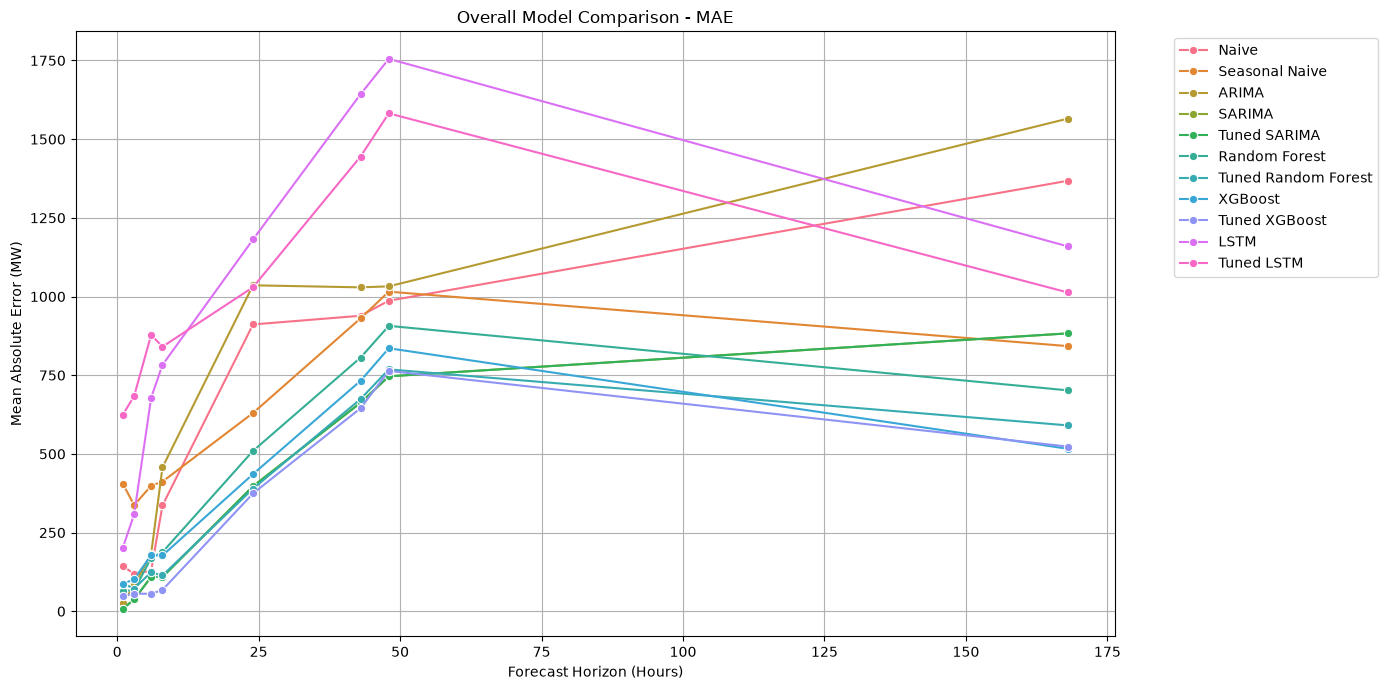

In [109]:
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=overall_results,
    x="Horizon",
    y="MAE",
    hue="Model",
    marker="o"
)

plt.title("Overall Model Comparison - MAE")
plt.xlabel("Forecast Horizon (Hours)")
plt.ylabel("Mean Absolute Error (MW)")
plt.grid(True)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()

plt.show()

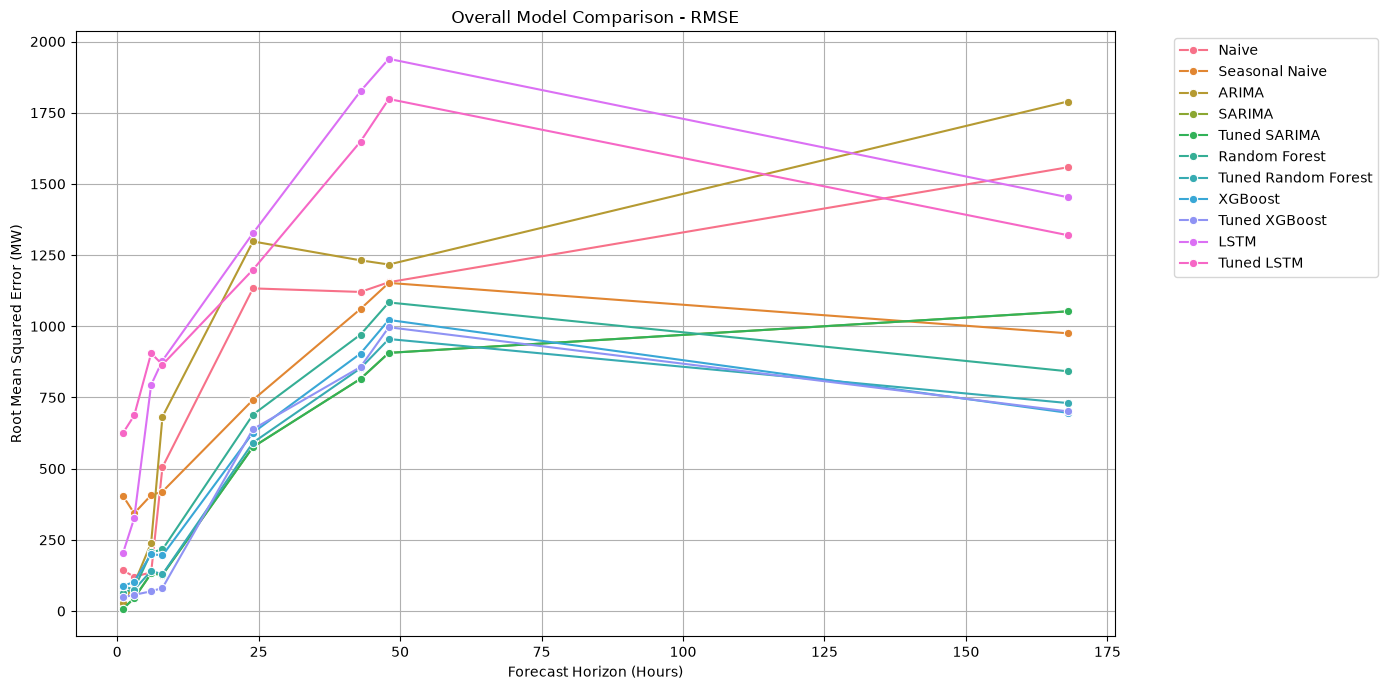

In [110]:
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=overall_results,
    x="Horizon",
    y="RMSE",
    hue="Model",
    marker="o"
)

plt.title("Overall Model Comparison - RMSE")
plt.xlabel("Forecast Horizon (Hours)")
plt.ylabel("Root Mean Squared Error (MW)")
plt.grid(True)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()

plt.show()

## 5.1 Final Test Evaluation
The best-performing models are retrained using the combined training and validation datasets. Their forecasting performance is then evaluated on the previously unseen test dataset.

In [111]:
# Combine training and validation datasets

train_val = pd.concat(
    [train, val]
)

# Final training features
X_train_val = train_val[feature_cols]

# Final training target
y_train_val = train_val["PJMW_MW"]

# Historical demand used for forecasting
final_history = train_val["PJMW_MW"].values

# Last datetime in the final training dataset
final_last_datetime = train_val.index[-1]

# Actual test values
test_actual = test["PJMW_MW"].values

# Test timestamps
test_dates = test.index

print("Combined Train + Validation:", train_val.shape)
print("Final Training Features:", X_train_val.shape)
print("Final Training Target:", y_train_val.shape)
print("Test Dataset:", test.shape)

print("\nFinal training ends at:", final_last_datetime)
print("Test begins at:", test_dates[0])

Combined Train + Validation: (121603, 17)
Final Training Features: (121603, 16)
Final Training Target: (121603,)
Test Dataset: (21461, 17)

Final training ends at: 2016-02-20 19:00:00
Test begins at: 2016-02-20 20:00:00


## Step 2 — Retraining Final Models
The selected forecasting models are retrained using the combined training and validation dataset. The previously selected optimal hyperparameters are retained.

In [112]:
# Retrain Tuned XGBoost using Train + Validation data

final_xgb_model = XGBRegressor(
    **best_xgb_config,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

final_xgb_model.fit(
    X_train_val,
    y_train_val
)

print("Final Tuned XGBoost model trained successfully.")

Final Tuned XGBoost model trained successfully.


In [113]:
# Retrain Tuned Random Forest using Train + Validation data

final_rf_model = RandomForestRegressor(
    **best_rf_config,
    random_state=42,
    n_jobs=-1
)

final_rf_model.fit(
    X_train_val,
    y_train_val
)

print("Final Tuned Random Forest model trained successfully.")

Final Tuned Random Forest model trained successfully.


In [114]:
# Use the most recent one year of Train + Validation data

final_sarima_history = final_history[-8760:]

# Build final SARIMA model using the best parameters

final_sarima_model = SARIMAX(
    final_sarima_history,
    order=best_sarima_order,
    seasonal_order=best_sarima_seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False
)

# Fit the final model

final_sarima_fit = final_sarima_model.fit(
    disp=False
)

print("Final Tuned SARIMA model trained successfully.")

Final Tuned SARIMA model trained successfully.


## Step 3 — Test Dataset Forecasting
The final trained models generate recursive multi-step forecasts for the unseen test dataset. Forecast performance is evaluated at multiple horizons using MAE, RMSE, and MAPE.

In [115]:
# Forecast horizons for final test evaluation

test_evaluation_horizons = [1, 3, 6, 8, 24, 43, 48, 168]

max_test_horizon = max(test_evaluation_horizons)

# Tuned XGBoost forecast
final_xgb_predictions = xgboost_forecast(
    history=final_history,
    last_datetime=final_last_datetime,
    horizon=max_test_horizon,
    model=final_xgb_model
)

# Tuned Random Forest forecast
final_rf_predictions = random_forest_forecast(
    history=final_history,
    last_datetime=final_last_datetime,
    horizon=max_test_horizon,
    model=final_rf_model
)

# Tuned SARIMA forecast
final_sarima_predictions = np.array(
    final_sarima_fit.forecast(
        steps=max_test_horizon
    )
)

print("All final model forecasts generated successfully.")

All final model forecasts generated successfully.


In [116]:
# Store final test results

final_test_results = []

final_predictions_dict = {
    "Tuned XGBoost": final_xgb_predictions,
    "Tuned Random Forest": final_rf_predictions,
    "Tuned SARIMA": final_sarima_predictions
}

for model_name, predictions in final_predictions_dict.items():

    for horizon in test_evaluation_horizons:

        actual = test_actual[:horizon]
        predicted = predictions[:horizon]

        mae, rmse, mape = calculate_metrics(
            actual,
            predicted
        )

        final_test_results.append({
            "Model": model_name,
            "Horizon": horizon,
            "MAE": mae,
            "RMSE": rmse,
            "MAPE": mape
        })

# Convert results into DataFrame

final_test_results_df = pd.DataFrame(
    final_test_results
)

final_test_results_df

,Model,Horizon,MAE,RMSE,MAPE
0,Tuned XGBoost,1,38.429199,38.429199,0.748669
1,Tuned XGBoost,3,135.475098,152.594728,2.707222
2,Tuned XGBoost,6,142.427083,155.640243,2.973979
3,Tuned XGBoost,8,118.012756,136.923729,2.493502
4,Tuned XGBoost,24,85.168966,137.879097,1.712216
5,Tuned XGBoost,43,216.943711,303.638334,4.035470
6,Tuned XGBoost,48,225.527201,306.361426,4.189360
7,Tuned XGBoost,168,399.524774,504.917965,6.625277
8,Tuned Random Forest,1,108.623512,108.623512,2.116180
9,Tuned Random Forest,3,247.952242,267.300877,4.946011


In [117]:
# Compare models using average test metrics

final_test_model_comparison = (
    final_test_results_df
    .groupby("Model")
    .agg({
        "MAE": "mean",
        "RMSE": "mean",
        "MAPE": "mean"
    })
    .reset_index()
    .sort_values("MAE")
    .reset_index(drop=True)
)

final_test_model_comparison

,Model,MAE,RMSE,MAPE
0,Tuned SARIMA,145.037709,178.177417,2.836906
1,Tuned XGBoost,170.188599,217.048090,3.185712
2,Tuned Random Forest,312.358182,338.306980,6.287097


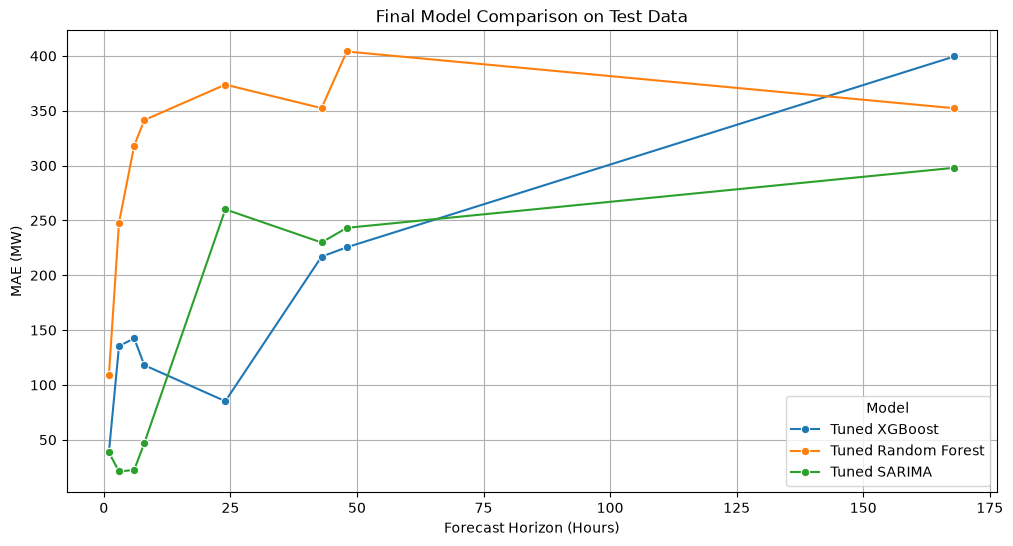

In [118]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=final_test_results_df,
    x="Horizon",
    y="MAE",
    hue="Model",
    marker="o"
)

plt.title("Final Model Comparison on Test Data")
plt.xlabel("Forecast Horizon (Hours)")
plt.ylabel("MAE (MW)")
plt.grid(True)
plt.show()

## Stage 5.2 — Save the Final Model
We will save only the final SARIMA model and the information required by the application.

In [119]:
import os
import joblib

os.makedirs("artifacts/models", exist_ok=True)

print("Model folder created successfully.")

Model folder created successfully.


In [120]:
# Save our final trained SARIMA model

final_sarima_fit.save(
    "artifacts/models/final_sarima_model.pkl"
)

print("Final Tuned SARIMA model saved successfully.")

Final Tuned SARIMA model saved successfully.


In [121]:
# Save forecasting metadata

forecast_metadata = {
    "last_datetime": final_last_datetime,
    "model_name": "Tuned SARIMA",
    "forecast_frequency": "Hourly"
}

joblib.dump(
    forecast_metadata,
    "artifacts/models/forecast_metadata.pkl"
)

print("Forecast metadata saved successfully.")

Forecast metadata saved successfully.


In [122]:
# Save historical demand data

train_val[["PJMW_MW"]].to_csv(
    "artifacts/final_training_history.csv"
)

print("Historical demand data saved successfully.")

Historical demand data saved successfully.


In [123]:
# Verify saved files

print("Files inside artifacts/models:\n")

for file in os.listdir("artifacts/models"):
    print(file)

print("\nOther artifact files:\n")

for file in os.listdir("artifacts"):
    if os.path.isfile(os.path.join("artifacts", file)):
        print(file)

Files inside artifacts/models:

final_sarima_model.pkl
forecast_metadata.pkl

Other artifact files:

final_training_history.csv
processed_data.csv
README.txt


In [124]:
# Load saved SARIMA model

from statsmodels.tsa.statespace.sarimax import SARIMAXResults

loaded_sarima_model = SARIMAXResults.load(
    "artifacts/models/final_sarima_model.pkl"
)

# Test a forecast for the next 5 hours

test_forecast = loaded_sarima_model.forecast(steps=5)

print("Next 5 hours forecast:")
print(test_forecast)

Next 5 hours forecast:
[5094.51689306 5061.69232918 4921.95546405 4718.52516285 4517.90051262]


In [140]:
# Create a smaller version of the SARIMA model
compact_model_path = "artifacts/models/compact_sarima_model.pkl"
final_model.save(compact_model_path, remove_data=True)
print("Compact model saved successfully!")

Compact model saved successfully!


In [141]:
from pathlib import Path
model_path = Path("artifacts/models/compact_sarima_model.pkl")
print(f"Compact model size: {model_path.stat().st_size / (1024**2):.2f} MB")

Compact model size: 531.83 MB


In [142]:
from statsmodels.tsa.statespace.sarimax import SARIMAXResults
compact_model = SARIMAXResults.load(compact_model_path)
test_forecast = compact_model.forecast(steps=5)
print(test_forecast)

TypeError: object of type 'NoneType' has no len()

## 5.3 Forecasting Function
This function loads the final trained SARIMA model and generates hourly electricity demand forecasts for any positive integer forecast horizon specified by the user.

In [125]:
import pandas as pd
import numpy as np

from statsmodels.tsa.statespace.sarimax import SARIMAXResults

In [126]:
# Load final saved SARIMA model

final_model = SARIMAXResults.load(
    "artifacts/models/final_sarima_model.pkl"
)

# Load forecasting metadata

forecast_metadata = joblib.load(
    "artifacts/models/forecast_metadata.pkl"
)

# Load historical demand

historical_data = pd.read_csv(
    "artifacts/final_training_history.csv",
    index_col=0,
    parse_dates=True
)

print("Model loaded successfully.")
print("Historical data loaded successfully.")
print("Last historical timestamp:", forecast_metadata["last_datetime"])

Model loaded successfully.
Historical data loaded successfully.
Last historical timestamp: 2016-02-20 19:00:00


In [127]:
def forecast_electricity_demand(horizon, model=final_model):

    # Validate forecast horizon
    if not isinstance(horizon, (int, np.integer)) or isinstance(horizon, bool):
        raise ValueError("Forecast horizon must be a positive integer.")

    if horizon <= 0:
        raise ValueError("Forecast horizon must be greater than zero.")

    # Get last historical datetime
    last_datetime = pd.Timestamp(
        forecast_metadata["last_datetime"]
    )

    # Generate future hourly timestamps
    future_dates = pd.date_range(
        start=last_datetime + pd.Timedelta(hours=1),
        periods=horizon,
        freq="h"
    )

    # Generate forecasts
    predictions = model.forecast(
        steps=horizon
    )

    # Create forecast DataFrame
    forecast_df = pd.DataFrame({
        "Datetime": future_dates,
        "Predicted_PJMW_MW": np.asarray(predictions)
    })

    return forecast_df

In [128]:
# Forecast the next 5 hours

forecast_5_hours = forecast_electricity_demand(5)

forecast_5_hours

,Datetime,Predicted_PJMW_MW
0,2016-02-20 20:00:00,5094.516893
1,2016-02-20 21:00:00,5061.692329
2,2016-02-20 22:00:00,4921.955464
3,2016-02-20 23:00:00,4718.525163
4,2016-02-21 00:00:00,4517.900513


In [130]:
# Forecast the next 24 hours

forecast_24_hours = forecast_electricity_demand(24)

print("Number of predictions:", len(forecast_24_hours))

forecast_24_hours.head(10)

Number of predictions: 24


,Datetime,Predicted_PJMW_MW
0,2016-02-20 20:00:00,5094.516893
1,2016-02-20 21:00:00,5061.692329
2,2016-02-20 22:00:00,4921.955464
3,2016-02-20 23:00:00,4718.525163
4,2016-02-21 00:00:00,4517.900513
5,2016-02-21 01:00:00,4390.264920
6,2016-02-21 02:00:00,4354.886157
7,2016-02-21 03:00:00,4383.128638
8,2016-02-21 04:00:00,4465.927798
9,2016-02-21 05:00:00,4617.912217


In [131]:
# Forecast the next 100 hours

forecast_100_hours = forecast_electricity_demand(100)

print("Number of predictions:", len(forecast_100_hours))

forecast_100_hours.head()

Number of predictions: 100


,Datetime,Predicted_PJMW_MW
0,2016-02-20 20:00:00,5094.516893
1,2016-02-20 21:00:00,5061.692329
2,2016-02-20 22:00:00,4921.955464
3,2016-02-20 23:00:00,4718.525163
4,2016-02-21 00:00:00,4517.900513


In [132]:
# Test invalid forecast horizons

invalid_horizons = [0, -5, 2.5, "24"]

for horizon in invalid_horizons:

    try:
        forecast_electricity_demand(horizon)

    except ValueError as error:
        print(f"Input {horizon}: {error}")

Input 0: Forecast horizon must be greater than zero.
Input -5: Forecast horizon must be greater than zero.
Input 2.5: Forecast horizon must be a positive integer.
Input 24: Forecast horizon must be a positive integer.


In [133]:
# Verify forecast output

assert len(forecast_5_hours) == 5
assert len(forecast_24_hours) == 24
assert len(forecast_100_hours) == 100

assert forecast_100_hours["Datetime"].is_monotonic_increasing

assert forecast_100_hours["Datetime"].diff().dropna().eq(
    pd.Timedelta(hours=1)
).all()

assert forecast_100_hours["Predicted_PJMW_MW"].notna().all()

print("All forecasting function tests passed successfully!")

All forecasting function tests passed successfully!


## 5.4 Forecast Visualization
Visualize historical electricity demand along with future predicted demand to understand the forecast trend.

In [134]:
import matplotlib.pyplot as plt

In [135]:
def plot_electricity_forecast(forecast_df, historical_data=historical_data):

    # Display the last 168 hours of historical data
    history_to_plot = historical_data.tail(168)

    plt.figure(figsize=(14, 6))

    # Plot historical demand
    plt.plot(
        history_to_plot.index,
        history_to_plot["PJMW_MW"],
        label="Historical Demand",
        color="blue"
    )

    # Plot forecast
    plt.plot(
        forecast_df["Datetime"],
        forecast_df["Predicted_PJMW_MW"],
        label="Forecasted Demand",
        color="red",
        linestyle="--"
    )

    # Mark forecast start
    plt.axvline(
        x=forecast_df["Datetime"].iloc[0],
        color="black",
        linestyle=":",
        label="Forecast Start"
    )

    plt.title("Electricity Demand Forecast")
    plt.xlabel("Datetime")
    plt.ylabel("Electricity Demand (MW)")

    plt.legend()
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.tight_layout()

    plt.show()

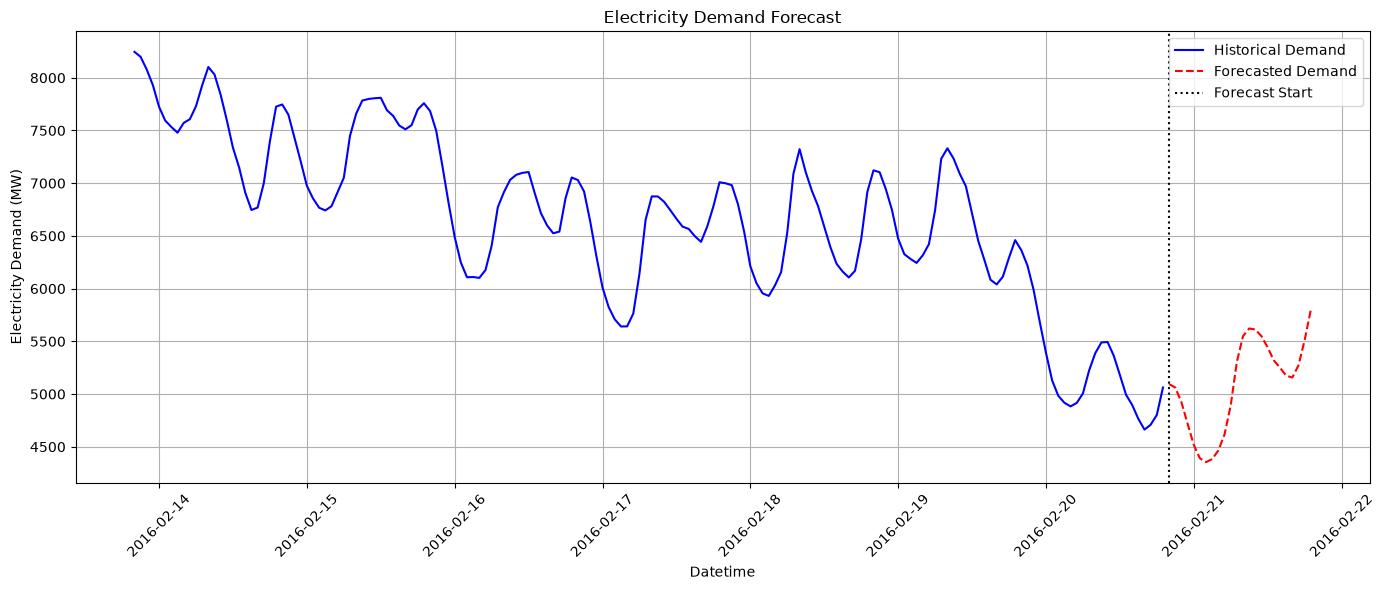

In [136]:
# Generate a 24-hour forecast

forecast_24_hours = forecast_electricity_demand(24)

# Plot the forecast

plot_electricity_forecast(forecast_24_hours)

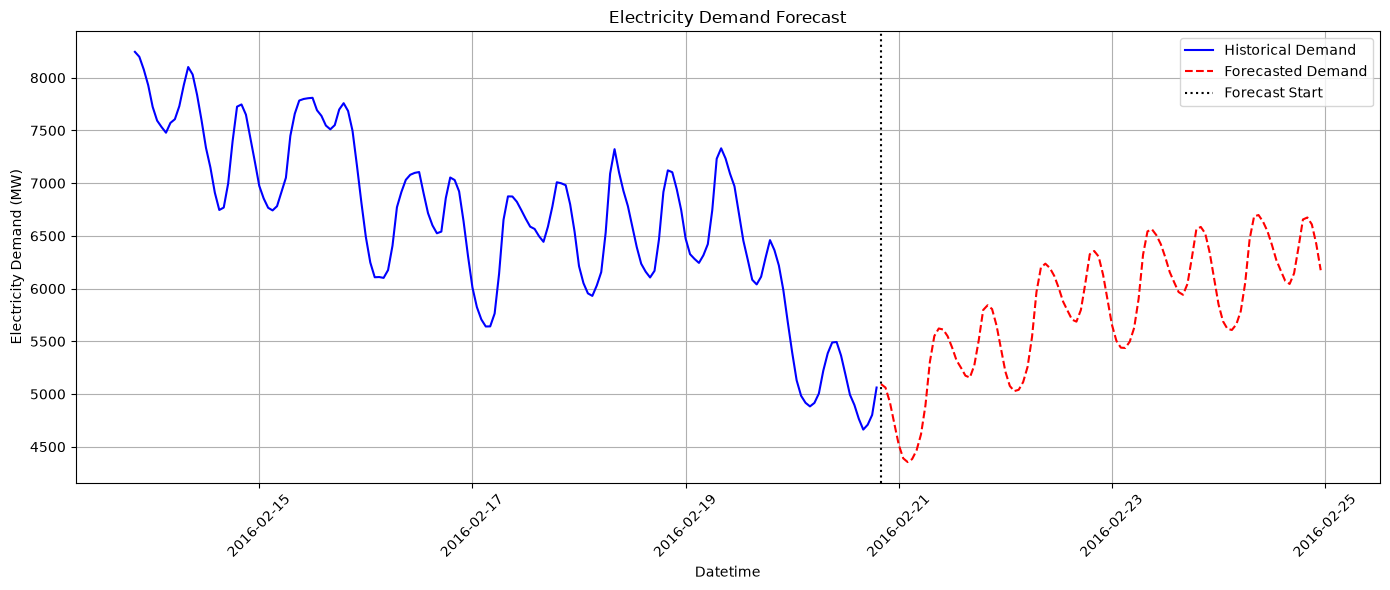

In [137]:
# Generate a 100-hour forecast

forecast_100_hours = forecast_electricity_demand(100)

# Plot the forecast

plot_electricity_forecast(forecast_100_hours)

In [138]:
assert len(forecast_24_hours) == 24
assert len(forecast_100_hours) == 100

print("Forecast visualizations generated successfully!")

Forecast visualizations generated successfully!
